# Network Traffic Pattern Mining and Intrusion Classification

**Analytics and Systems of Big Data · IIITDM Kancheepuram**  
**Gyan Chandra — CS23I1053** · **ALURI VENKAT VAIBHAV — CS23I1040**  
Project stage: concepts through classification. Detailed report deadline: **26 October 2026**.

We study labelled network flows, find recurring traffic combinations, and compare binary intrusion classifiers. `label=1` means attack; `label=0` means normal. Association mining describes co-occurrence; classification predicts a held-out flow's label.

This notebook contains the implementation, measured experiments, correctness checks and findings. Classification uses all **eligible cleaned training rows**, whereas frequent-pattern experiments use explicitly sized training subsets. Raw CSV bytes are preserved. Dataset roles and source verification are documented in Section 2.

Course source reviewed: `BigData_mid+end_compressed.pdf`, 224 pages, B. Sivaselvan. Page numbers here are PDF page positions. The coverage table near the end distinguishes implemented concepts from concepts explained only. Random Forest is the additional classification concept beyond the supplied classification material.

## 1. Environment and experiment contract

Run cells in order from a fresh kernel, with this notebook's folder as the working directory. Use Python from `.venv` as the notebook kernel. Exact tested versions and commands appear in Section 11. No GPU is needed. We use seed **42**, at most two forest workers and bounded itemset lengths to keep execution practical on a student laptop.

The downloader contacts only the two requested CSV URLs for data files. It follows redirects, limits attempts, uses connect/read and total-download timeouts, checks file size and CSV structure, and writes through a temporary file. A cached raw file is checked and reused without alteration. If data cannot be obtained, execution stops with the real download error; there is no synthetic replacement for the dataset.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'

import sys, platform, time, math, hashlib, csv, json, warnings
from pathlib import Path
from datetime import datetime, timezone, timedelta
from itertools import combinations
from collections import Counter, defaultdict
from importlib.metadata import version
from urllib.parse import urlsplit, urlunsplit

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
from IPython.display import display, Markdown
from scipy.special import logsumexp
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve)
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori as library_apriori, fpgrowth as library_fpgrowth

SEED = 42
rng = np.random.default_rng(SEED)
RUN_START = time.perf_counter()
ROOT = Path.cwd()
DATA = ROOT / 'data'
DATA.mkdir(exist_ok=True)
pd.set_option('display.max_rows', 18)
pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 150)
pd.set_option('display.max_colwidth', 95)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn',
            'mlxtend', 'nbformat', 'nbclient', 'ipykernel', 'requests', 'psutil']
tested_versions = {name: version(name) for name in packages}
print(f'OS: {platform.platform()} | Python: {platform.python_version()}')
print(f'Kernel executable: {sys.executable}')
print(f'Logical CPUs: {os.cpu_count()} | RAM: {psutil.virtual_memory().total / 2**30:.1f} GiB')
print('Seed: 42; forest workers: 2; all timings are wall-clock seconds on this host.')
display(pd.DataFrame(tested_versions.items(), columns=['dependency', 'version']))

OS: Windows-11-10.0.26200-SP0 | Python: 3.13.12
Kernel executable: C:\Users\91995\Desktop\Big Data Lab\Network-Traffic-Pattern-Mining-and-Intrusion-Classification\.venv\Scripts\python.exe
Logical CPUs: 12 | RAM: 15.2 GiB
Seed: 42; forest workers: 2; all timings are wall-clock seconds on this host.


,dependency,version
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,mlxtend,0.25.0
7,nbformat,5.11.1
8,nbclient,0.11.0
9,ipykernel,7.4.0


## 2. Dataset, provenance and split assignment

[UNSW-NB15](https://research.unsw.edu.au/projects/unsw-nb15-dataset) describes normal and attack traffic from the UNSW Canberra cyber range. The [Mireu-Lab mirror at the pinned revision](https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/tree/3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0) has filenames reversed relative to the expected roles: mirror `test.csv` supplies local `data/UNSW_NB15_training-set.csv`, and mirror `train.csv` supplies local `data/UNSW_NB15_testing-set.csv`. The notebook **already used the correct roles**; this cleanup changes filenames and makes the mapping explicit. There are **175,341 raw training rows**, **99,607 eligible training rows** after the existing cleaning policy, and **82,332 test rows**.

An independent source review found that, after excluding `id`, all rows and all **44 common columns** exactly matched the **standard** configuration of [lacg030175/UNSW-NB15](https://huggingface.co/datasets/lacg030175/UNSW-NB15#configurations). This verifies agreement between the two mirrors; direct identity with original UNSW-hosted files remains **unverified**. Cleaning changes the training population, so published performance comparisons must account for the preprocessing difference. The source-review finding is recorded here; this kernel checks the pinned CSV hashes, schema and explicit row counts rather than repeating that cross-mirror review.


In [2]:
import tempfile

MIRROR_REVISION = '3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0'
SOURCES = {
    'training': {'local_file': 'UNSW_NB15_training-set.csv', 'mirror_file': 'test.csv',
                 'expected_rows': 175341,
                 'expected_sha256': 'bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa'},
    'testing': {'local_file': 'UNSW_NB15_testing-set.csv', 'mirror_file': 'train.csv',
                'expected_rows': 82332,
                'expected_sha256': '734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559'},
}
URLS = {spec['local_file']: f'https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/resolve/{MIRROR_REVISION}/{spec["mirror_file"]}'
        for spec in SOURCES.values()}
OFFICIAL_URL = 'https://research.unsw.edu.au/projects/unsw-nb15-dataset'
# Preserve the original 45-column schema and predictor order exactly.
EXPECTED_COLUMNS = """id dur proto service state spkts dpkts sbytes dbytes rate sttl dttl
sload dload sloss dloss sinpkt dinpkt sjit djit swin stcpb dtcpb dwin tcprtt synack
ackdat smean dmean trans_depth response_body_len ct_srv_src ct_state_ttl ct_dst_ltm
ct_src_dport_ltm ct_dst_sport_ltm ct_dst_src_ltm is_ftp_login ct_ftp_cmd ct_flw_http_mthd
ct_src_ltm ct_srv_dst is_sm_ips_ports attack_cat label""".split()
CAT_COLUMNS = ['proto', 'service', 'state']
PREDICTORS = [c for c in EXPECTED_COLUMNS if c not in {'id', 'attack_cat', 'label'}]
NUM_COLUMNS = [c for c in PREDICTORS if c not in CAT_COLUMNS]
session = requests.Session()
session.max_redirects = 6
session.headers['User-Agent'] = 'IIITDM-BigData-course-project/1.0'

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def verify_csv(p):
    # Reject HTML/error pages, malformed widths, truncated rows and changed schemas.
    with open(p, encoding='utf-8-sig', newline='') as f:
        reader = csv.reader(f, strict=True)
        header = next(reader, None)
        if header != EXPECTED_COLUMNS:
            raise ValueError(f'{p.name}: unexpected CSV header: {header}')
        rows = 0
        for row in reader:
            if len(row) != len(header):
                raise ValueError(f'{p.name}: row {rows + 2} has {len(row)} fields')
            rows += 1
    if rows < 1:
        raise ValueError(f'{p.name}: empty dataset')
    return rows

def validate_source_csv(p, spec):
    actual = sha256_file(p)
    if actual != spec['expected_sha256']:
        raise ValueError(f'{p.name}: SHA-256 mismatch; file left untouched. '
                         f'Expected {spec["expected_sha256"]}, found {actual}')
    rows = verify_csv(p)
    if rows != spec['expected_rows']:
        raise ValueError(f'{p.name}: expected {spec["expected_rows"]} rows, found {rows}')
    return rows, actual

def download_csv(role, spec):
    name = spec['local_file']
    dest, url = DATA/name, URLS[name]
    base_metadata = {'file': name, 'mirror_file': spec['mirror_file'], 'role': role,
                     'source_url': url, 'source_revision': MIRROR_REVISION,
                     'expected_sha256': spec['expected_sha256']}
    if dest.exists():
        rows, digest = validate_source_csv(dest, spec)  # Never replace a conflicting cache.
        return {**base_metadata, 'download': 'cached; raw preserved', 'rows_csv': rows,
                'sha256': digest, 'bytes': dest.stat().st_size,
                'download_commit': 'not captured on cached run; pinned hash verified'}
    last_error = None
    for attempt in range(1, 4):
        tmp = None
        try:
            started = time.perf_counter()
            with session.get(url, stream=True, allow_redirects=True, timeout=(15, 60)) as response:
                response.raise_for_status()
                if 'html' in response.headers.get('Content-Type', '').lower():
                    raise ValueError('HTML response instead of CSV')
                size = 0
                with tempfile.NamedTemporaryFile(dir=DATA, prefix=f'.{name}.', suffix='.part', delete=False) as f:
                    tmp = Path(f.name)
                    for block in response.iter_content(1024 * 256):
                        if time.perf_counter()-started > 240:
                            raise TimeoutError('total download exceeded 240 seconds')
                        size += len(block)
                        if size > 100 * 1024**2:
                            raise ValueError('CSV exceeds the 100 MiB safety bound')
                        f.write(block)
                row_count, digest = validate_source_csv(tmp, spec)
                final = urlsplit(response.url)
                metadata = {**base_metadata, 'download': f'downloaded, attempt {attempt}',
                            'final_url_without_query': urlunsplit((final.scheme, final.netloc, final.path, '', '')),
                            'download_commit': response.headers.get('X-Repo-Commit', 'not provided'),
                            'content_type': response.headers.get('Content-Type', 'not provided'),
                            'redirects': len(response.history), 'rows_csv': row_count,
                            'sha256': digest, 'bytes': size}
            # Atomic creation without overwriting any existing destination (same-directory hard link).
            try:
                os.link(tmp, dest)
            except FileExistsError:
                validate_source_csv(dest, spec)
                metadata['download'] = 'matching destination appeared; reused without alteration'
            return metadata
        except (requests.RequestException, OSError, ValueError, csv.Error, TimeoutError) as e:
            last_error = f'{type(e).__name__}: {e}'
            if attempt < 3:
                time.sleep(attempt)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    raise RuntimeError(f'Download blocked after 3 attempts: {url}\n{last_error}')

manifest = [download_csv(role, spec) for role, spec in SOURCES.items()]
raw_files = {name: pd.read_csv(DATA/name, low_memory=False) for name in URLS}
assert all(list(frame.columns) == EXPECTED_COLUMNS for frame in raw_files.values())
assert all(len(raw_files[row['file']]) == row['rows_csv'] for row in manifest)
train_name = SOURCES['training']['local_file']
test_name = SOURCES['testing']['local_file']
raw_train, raw_test = raw_files[train_name], raw_files[test_name]
assert len(raw_train) == SOURCES['training']['expected_rows'] == 175341
assert len(raw_test) == SOURCES['testing']['expected_rows'] == 82332

# Pinned metadata uses original mirror filenames, never the canonical local names.
mirror_provenance = {'pinned_mirror_revision': MIRROR_REVISION}
try:
    response = session.get(f'https://huggingface.co/api/datasets/Mireu-Lab/UNSW-NB15/tree/{MIRROR_REVISION}', timeout=(10, 30))
    response.raise_for_status()
    mirror_names = {spec['mirror_file'] for spec in SOURCES.values()}
    file_info = {entry['path']: entry for entry in response.json() if entry['path'] in mirror_names}
except (requests.RequestException, KeyError, ValueError) as e:
    file_info = {}
    mirror_provenance['metadata_error'] = f'{type(e).__name__}: {e}'
for row in manifest:
    row['mirror_lfs_sha256'] = file_info.get(row['mirror_file'], {}).get('lfs', {}).get('oid', 'unavailable')
    row['matches_mirror_hash'] = (row['sha256'] == row['mirror_lfs_sha256']) if row['mirror_lfs_sha256'] != 'unavailable' else None
    if row['mirror_lfs_sha256'] != 'unavailable':
        assert row['mirror_lfs_sha256'] == row['expected_sha256'], 'Pinned mirror hash changed unexpectedly'
        assert row['matches_mirror_hash']

display(pd.DataFrame(manifest)[['file', 'mirror_file', 'role', 'rows_csv', 'bytes', 'sha256', 'matches_mirror_hash']])
print('Pinned source URLs:')
for row in manifest:
    print(row['file'], '<-', row['mirror_file'], row['source_url'])
    print('SHA-256:', row['sha256'], '| mirror LFS SHA-256:', row['mirror_lfs_sha256'])
    print('Download state:', row['download'], '| reported download commit:', row['download_commit'])
print(json.dumps(mirror_provenance, indent=2))
schema = pd.DataFrame({'feature': EXPECTED_COLUMNS,
                      'training_dtype': [str(raw_train[c].dtype) for c in EXPECTED_COLUMNS],
                      'testing_dtype': [str(raw_test[c].dtype) for c in EXPECTED_COLUMNS],
                      'role': ['target' if c == 'label' else 'excluded' if c in {'id', 'attack_cat'}
                               else 'categorical predictor' if c in CAT_COLUMNS else 'numeric predictor'
                               for c in EXPECTED_COLUMNS]})
print('Complete schema (45 columns, 42 potential predictors):')
print(schema.to_string(index=False))
display(pd.DataFrame({role: raw_files[spec['local_file']]['label'].value_counts().sort_index()
                      for role, spec in SOURCES.items()}))
display(pd.DataFrame({role: raw_files[spec['local_file']]['attack_cat'].str.strip().value_counts()
                      for role, spec in SOURCES.items()}).fillna(0).astype(int))

,file,mirror_file,role,rows_csv,bytes,sha256,matches_mirror_hash
0,UNSW_NB15_training-set.csv,test.csv,training,175341,32293018,bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa,True
1,UNSW_NB15_testing-set.csv,train.csv,testing,82332,15380800,734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559,True


Pinned source URLs:
UNSW_NB15_training-set.csv <- test.csv https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/resolve/3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0/test.csv
SHA-256: bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa | mirror LFS SHA-256: bec7dd5ec88dc2a0ccc7a07879d338395ed7421750f675fd0339e07dfe0648fa
Download state: cached; raw preserved | reported download commit: not captured on cached run; pinned hash verified
UNSW_NB15_testing-set.csv <- train.csv https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/resolve/3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0/train.csv
SHA-256: 734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559 | mirror LFS SHA-256: 734fe6642edf758f7c94d7d9149426b49d202fe8e7bf0bef47392489c3c0a559
Download state: cached; raw preserved | reported download commit: not captured on cached run; pinned hash verified
{
  "pinned_mirror_revision": "3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0"
}
Complete schema (45 columns, 42 potential predictors):

,training,testing
label,,
0,56000,37000
1,119341,45332


,training,testing
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


## 3. KDD workflow and data quality

Our KDD workflow is **understand → clean/integrate schemas → select traffic attributes → transform → mine/train → evaluate → present** (slides pp. 48–64). We align schemas without pooling the two partitions.

Policies fixed before model selection:

* Missing/invalid predictor values and ±infinity become missing; training-fitted medians fill numerical columns, and a missing-category token fills categorical columns. Invalid targets are excluded and counted, never guessed.
* Counts, durations and rates must be nonnegative; TTL must be within 0–255 and `is_sm_ips_ports` must be binary. The dataset's `is_ftp_login=2` is retained as observed because it may reflect feature coding. `service='-'` means unspecified service and remains a category.
* **Extreme but valid traffic is retained.** Long flows, high rates and byte volumes can be attacks. We use log axes/log transformations without deleting such observations.
* Record identity uses all 42 traffic predictors, excluding `id`, `attack_cat` and the target. We remove all ambiguous predictor groups with conflicting training labels, keep one copy of each remaining training predictor row, and purge training identities occurring in the test file. The test file keeps its valid rows and multiplicities so evaluation retains its observed distribution. We also report a unique-test-row sensitivity check.
* Hashes accelerate identity comparison; we verify their distinct-key count against exact `drop_duplicates` on the combined data before using them. This detects collisions on these actual records.

In [3]:
def clean_frame(raw, name):
    frame = raw.copy(deep=True)
    audit = {'split': name, 'raw_rows': len(raw), 'raw_missing_cells': int(raw.isna().sum().sum()),
             'raw_exact_duplicates_excluding_id': int(raw.drop(columns='id').duplicated().sum())}
    for c in CAT_COLUMNS + ['attack_cat']:
        values = frame[c].astype('string').str.strip()
        frame[c] = values.mask(values.isin(['', '?', 'null', 'None'])).astype(object)
        frame[c] = frame[c].where(pd.notna(frame[c]), np.nan)
    bad_parse = infinite = negative = range_errors = 0
    for c in NUM_COLUMNS:
        numeric = pd.to_numeric(frame[c], errors='coerce')
        bad_parse += int((frame[c].notna() & numeric.isna()).sum())
        inf_mask = np.isinf(numeric.to_numpy(dtype=float))
        infinite += int(inf_mask.sum())
        numeric = numeric.mask(inf_mask)
        negative += int((numeric < 0).sum())
        numeric = numeric.mask(numeric < 0)
        if c in ['sttl', 'dttl']:
            invalid = numeric.notna() & ~numeric.between(0, 255)
        elif c == 'is_sm_ips_ports':
            invalid = numeric.notna() & ~numeric.isin([0, 1])
        else:
            invalid = pd.Series(False, index=frame.index)
        range_errors += int(invalid.sum())
        frame[c] = numeric.mask(invalid)
    labels = pd.to_numeric(frame['label'], errors='coerce')
    valid_target = labels.isin([0, 1])
    audit.update({'parse_failures': bad_parse, 'infinite_cells': infinite,
                  'negative_cells': negative, 'domain_violations': range_errors,
                  'invalid_targets_removed': int((~valid_target).sum())})
    frame = frame.loc[valid_target].copy()
    frame['label'] = labels.loc[valid_target].astype('int8')
    audit['missing_predictor_cells_after_cleaning'] = int(frame[PREDICTORS].isna().sum().sum())
    audit['duplicate_predictor_rows'] = int(frame.duplicated(subset=PREDICTORS).sum())
    # attack_cat is checked for interpretation only; never passed to a classifier.
    known = frame['attack_cat'].notna()
    audit['label_category_disagreements'] = int(((frame.loc[known, 'attack_cat'] != 'Normal').astype(int)
                                               != frame.loc[known, 'label']).sum())
    return frame.reset_index(drop=True), audit

train_clean, audit_train = clean_frame(raw_train, 'training source')
test_clean, audit_test = clean_frame(raw_test, 'testing source')
display(pd.DataFrame([audit_train, audit_test]).T)
identity_frames = pd.concat([train_clean[PREDICTORS], test_clean[PREDICTORS]], ignore_index=True)
identities = pd.util.hash_pandas_object(identity_frames, index=False)
exact_unique_count = len(identity_frames.drop_duplicates())
assert identities.nunique() == exact_unique_count, 'Hash collision detected; use exact identity joins.'
train_ids = identities.iloc[:len(train_clean)].reset_index(drop=True)
test_ids = identities.iloc[len(train_clean):].reset_index(drop=True)
group_labels = pd.DataFrame({'identity': train_ids, 'label': train_clean['label']}).groupby('identity')['label'].nunique()
conflict_ids = set(group_labels[group_labels > 1].index)
ambiguous = train_ids.isin(conflict_ids)
duplicate = train_ids.duplicated(keep='first')
overlap = train_ids.isin(set(test_ids))
eligible = ~ambiguous & ~duplicate & ~overlap
train = train_clean.loc[eligible].reset_index(drop=True)
test = test_clean.copy()
train_identity = train_ids.loc[eligible].reset_index(drop=True)
test_identity = test_ids
quality_policy = pd.DataFrame([
    ('ambiguous training rows removed', int(ambiguous.sum())),
    ('ambiguous training identities', len(conflict_ids)),
    ('extra training predictor copies', int(duplicate.sum())),
    ('training rows overlapping test (before other exclusions)', int(overlap.sum())),
    ('distinct identities common to raw cleaned splits', len(set(train_ids) & set(test_ids))),
    ('training rows removed by union of all policies', int((~eligible).sum())),
    ('eligible training rows', len(train)),
    ('valid test rows retained', len(test)),
    ('unique test predictor identities', test_identity.nunique())], columns=['check / policy', 'count'])
display(quality_policy)
assert not (set(train_identity) & set(test_identity))
assert train_identity.is_unique
assert set(train['label']) == set(test['label']) == {0, 1}
assert not any(c in PREDICTORS for c in ['id', 'attack_cat', 'label'])
del identity_frames, identities, raw_files
print('Identity checks passed. Test multiplicities retained; exclusion counts can overlap.')

,0,1
split,training source,testing source
raw_rows,175341,82332
raw_missing_cells,0,0
raw_exact_duplicates_excluding_id,67601,26387
parse_failures,0,0
infinite_cells,0,0
negative_cells,0,0
domain_violations,0,0
invalid_targets_removed,0,0
missing_predictor_cells_after_cleaning,0,0


,check / policy,count
0,ambiguous training rows removed,940
1,ambiguous training identities,229
2,extra training predictor copies,74301
3,training rows overlapping test (before other exclusions),10279
4,distinct identities common to raw cleaned splits,1302
5,training rows removed by union of all policies,75734
6,eligible training rows,99607
7,valid test rows retained,82332
8,unique test predictor identities,53946


Identity checks passed. Test multiplicities retained; exclusion counts can overlap.


## 4. Training exploration and transformations

These plots use eligible training data. We inspect imbalance, protocol usage, heavy-tailed byte counts and correlations. Correlation does not imply causation. We use descriptive statistics and keep attack extremes. Feature selection removes constant columns and numerical columns almost redundant with an earlier retained column (absolute Spearman correlation ≥0.995, estimated on up to 20,000 training rows). Selection is fitted inside each classifier pipeline, so validation and test rows cannot set this decision.

Trees use median imputation and one-hot categories, including grouping categories seen fewer than 20 times. Trees do not require scaling. The mixed Naive Bayes model uses log(1+x) for nonnegative numeric traffic, then training-fitted z-score normalization; its categorical likelihoods use additive smoothing. Association bins are fitted separately on training traffic and never become classifier label-derived inputs.

,count,mean,std,min,25%,50%,75%,95%,99%,max
dur,99607.0,1.277,4.950,0.0,0.006,0.388,1.006,3.316,26.881,6.000000e+01
sbytes,99607.0,14785.029,231378.033,28.0,546.000,1004.000,2934.000,34710.000,136021.000,1.296523e+07
dbytes,99607.0,25427.486,181731.741,0.0,268.000,646.000,3380.000,59460.000,645754.000,1.465555e+07
rate,99607.0,26854.051,98780.224,0.0,25.608,74.650,2933.376,166666.661,500000.001,1.000000e+06
sttl,99607.0,134.754,107.128,0.0,31.000,62.000,254.000,254.000,254.000,2.550000e+02
ct_srv_src,99607.0,5.061,6.346,1.0,1.000,3.000,6.000,15.000,34.000,6.300000e+01


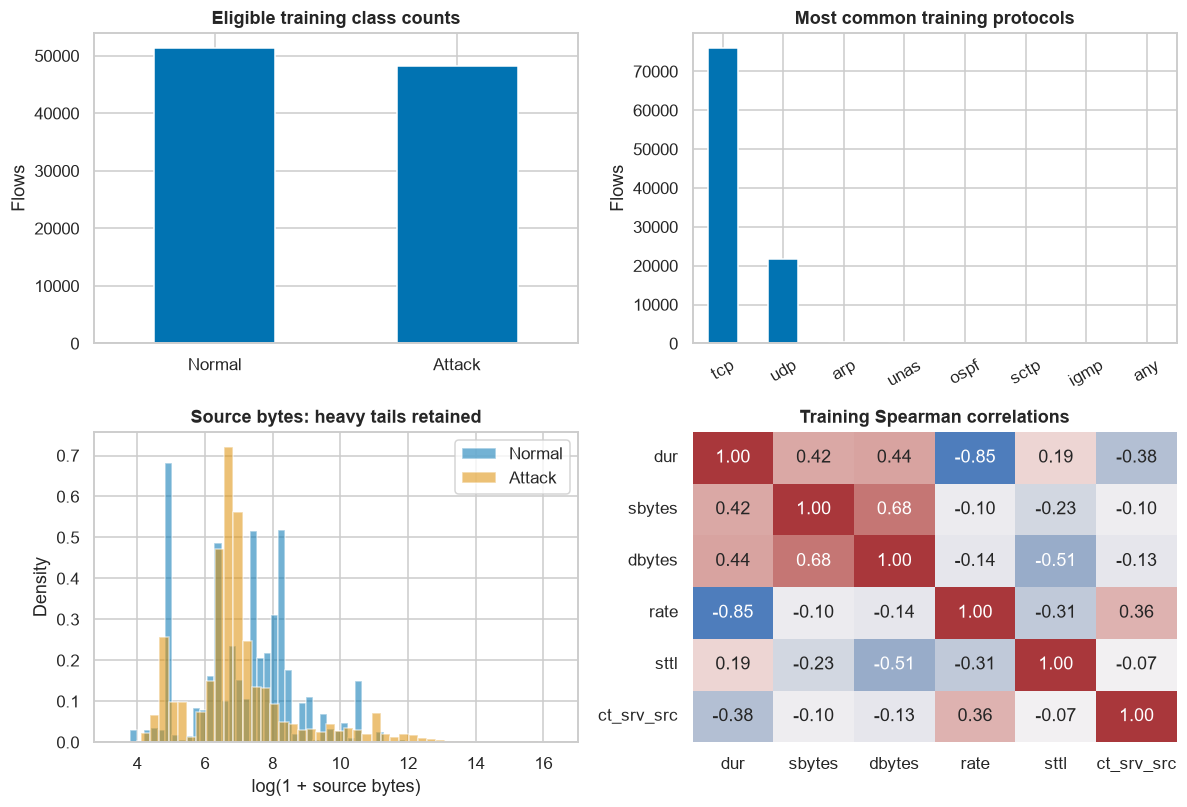

The eligible training attack prevalence is **48.4%**. A majority baseline is necessary because accuracy alone can hide class errors. Byte distributions are displayed on a log scale; no large valid values were removed.

,rows,role
training fit,79685,fit preprocessing/models
training validation,19922,select settings by macro F1
test,82332,final evaluation only


Selection example fitted on 79,685 fit rows: 42 -> 40 raw traffic features.
Constants: [] | near-redundant numeric columns: ['ct_ftp_cmd', 'ct_flw_http_mthd']


,feature,fit_zscore_mean,fit_zscore_std
0,dur,0.0,1.0
1,sbytes,-0.0,1.0
2,rate,0.0,1.0


In [4]:
describe_features = ['dur', 'sbytes', 'dbytes', 'rate', 'sttl', 'ct_srv_src']
display(train[describe_features].describe(percentiles=[.25, .5, .75, .95, .99]).T.round(3))
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
train['label'].map({0: 'Normal', 1: 'Attack'}).value_counts().reindex(['Normal', 'Attack']).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title='Eligible training class counts', ylabel='Flows', xlabel='')
train['proto'].value_counts().head(8).plot.bar(ax=axes[0, 1], rot=30)
axes[0, 1].set(title='Most common training protocols', ylabel='Flows', xlabel='')
for label, name in [(0, 'Normal'), (1, 'Attack')]:
    axes[1, 0].hist(np.log1p(train.loc[train.label == label, 'sbytes'].dropna()), bins=45,
                    density=True, alpha=.55, label=name)
axes[1, 0].set(title='Source bytes: heavy tails retained', xlabel='log(1 + source bytes)', ylabel='Density')
axes[1, 0].legend()
sns.heatmap(train[describe_features].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('Training Spearman correlations')
fig.tight_layout()
plt.show()
display(Markdown(f'The eligible training attack prevalence is **{train.label.mean():.1%}**. '
                 'A majority baseline is necessary because accuracy alone can hide class errors. '
                 'Byte distributions are displayed on a log scale; no large valid values were removed.'))

X_train, y_train = train[PREDICTORS].copy(), train['label'].copy()
# Only hold-out identity checks have used test predictors so far. No model decisions use test labels.
X_test, y_test = test[PREDICTORS].copy(), test['label'].copy()
fit_idx, val_idx = train_test_split(np.arange(len(train)), test_size=.20, random_state=SEED, stratify=y_train)
X_fit, X_val = X_train.iloc[fit_idx], X_train.iloc[val_idx]
y_fit, y_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]
assert not (set(train_identity.iloc[fit_idx]) & set(train_identity.iloc[val_idx]))
display(pd.DataFrame({'rows': [len(X_fit), len(X_val), len(X_test)],
                      'role': ['fit preprocessing/models', 'select settings by macro F1', 'final evaluation only']},
                     index=['training fit', 'training validation', 'test']))

class TrafficSelector(TransformerMixin, BaseEstimator):
    def __init__(self, correlation_threshold=.995, sample_size=20000):
        self.correlation_threshold = correlation_threshold
        self.sample_size = sample_size
    def fit(self, X, y=None):
        assert not set(X.columns) & {'id', 'attack_cat', 'label'}
        self.fit_rows_ = len(X)
        self.constants_ = [c for c in X if X[c].nunique(dropna=False) <= 1]
        numeric = [c for c in X.select_dtypes(include=np.number) if c not in self.constants_]
        sample = X[numeric].sample(min(self.sample_size, len(X)), random_state=SEED)
        corr = sample.corr(method='spearman').abs()
        kept, self.redundant_ = [], []
        for c in numeric:
            if any(pd.notna(corr.loc[c, old]) and corr.loc[c, old] >= self.correlation_threshold for old in kept):
                self.redundant_.append(c)
            else:
                kept.append(c)
        self.columns_ = [c for c in X if c not in self.constants_ + self.redundant_]
        return self
    def transform(self, X):
        return X.loc[:, self.columns_].copy()
    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)

selector_demo = TrafficSelector().fit(X_fit)
print(f'Selection example fitted on {selector_demo.fit_rows_:,} fit rows: {len(PREDICTORS)} -> {len(selector_demo.columns_)} raw traffic features.')
print('Constants:', selector_demo.constants_, '| near-redundant numeric columns:', selector_demo.redundant_)
# Normalization demonstration uses fit rows only and preserves large values.
normalization_demo = Pipeline([('impute', SimpleImputer(strategy='median')),
                               ('log', FunctionTransformer(np.log1p)), ('zscore', StandardScaler())])
normalized_fit = normalization_demo.fit_transform(X_fit[['dur', 'sbytes', 'rate']])
display(pd.DataFrame({'feature': ['dur', 'sbytes', 'rate'], 'fit_zscore_mean': normalized_fit.mean(axis=0),
                      'fit_zscore_std': normalized_fit.std(axis=0)}).round(6))

### 4.1 Training-fit byte distributions

The boxplot uses all nonmissing **training-fit** source-byte values, including valid extremes. Its whiskers use the usual 1.5-IQR rule; points beyond them remain observations. The scatter uses at most **3,000** training-fit rows with both byte counts present, sampled with **seed 42**. Both axes show $\log(1+x)$ (`log1p`, natural logarithm) to make the large byte range readable. Class colours are descriptive labels, never classifier inputs. The actual sizes and a short interpretation are reported below.

The examples here and in Sections 4.2–4.4 follow the supplied course PDF (pages 30–44 and 57–64) and the relevant notebooks inside `Lab3.zip`: `Lab3/CS23I1053_Advanced_Data_Visualization_Assignment (1).ipynb`, `Lab4/Task1/CS23I1053_Data_Preprocessing_Normalization_Binning_Assignment.ipynb`, and the Lab5 preprocessing examples. They are adapted to the existing traffic data; no lab dataset or exported lab result is added.

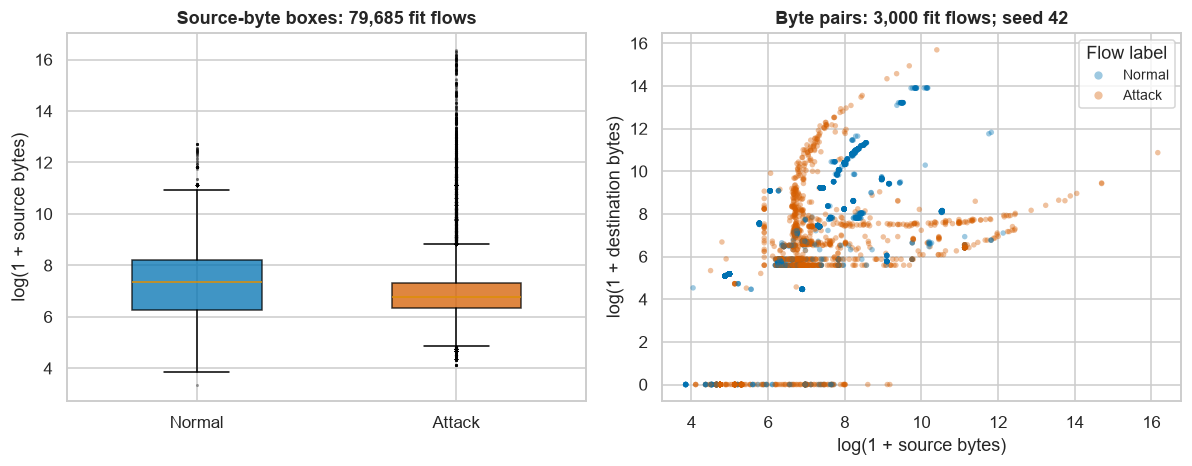

,n,q25,median,q75,scatter_n,log_byte_correlation
Class,,,,,,
Normal,41092,6.282,7.340,8.193,1510,0.649
Attack,38593,6.337,6.772,7.331,1490,0.492


**Observed:** attack flows have a **lower** median log source-byte count (6.772) than normal flows (7.340). The middle 50% ranges overlap. The scatter has **29 shared one-log-unit regions** occupied by both classes; its within-class log-byte correlations are **0.649** (Normal) and **0.492** (Attack). These byte features show traffic structure, but this sampled view does not establish perfect class separation. Boxplot: 79,685/79,685 fit rows; scatter: 3,000/79,685 complete fit pairs. Only the scatter is sampled; seed 42, no clipping.

In [5]:
# Integrity fingerprints only: held-out values are not used to fit these demonstrations.
def frame_fingerprint(frame):
    return hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).to_numpy().tobytes()).hexdigest()

refinement_frames = {'train': train, 'test': test, 'X_train': X_train, 'y_train': y_train,
                     'X_fit': X_fit, 'y_fit': y_fit, 'X_val': X_val, 'y_val': y_val,
                     'X_test': X_test, 'y_test': y_test}
refinement_before = {name: frame_fingerprint(frame) for name, frame in refinement_frames.items()}
byte_view = X_fit[['sbytes', 'dbytes']].copy()
byte_view['Class'] = y_fit.map({0: 'Normal', 1: 'Attack'})
box_view = byte_view.dropna(subset=['sbytes']).copy()
scatter_pool = byte_view.dropna(subset=['sbytes', 'dbytes'])
scatter_view = scatter_pool.sample(n=min(3000, len(scatter_pool)), random_state=SEED).copy()
assert len(scatter_view) <= 3000 and scatter_view.index.isin(X_fit.index).all()
assert scatter_view.index.equals(scatter_pool.sample(n=len(scatter_view), random_state=SEED).index)
assert np.isfinite(box_view.sbytes).all() and np.isfinite(scatter_view[['sbytes', 'dbytes']]).all().all()
assert box_view.sbytes.ge(0).all() and scatter_view[['sbytes', 'dbytes']].ge(0).all().all()
box_view['log_sbytes'] = np.log1p(box_view.sbytes)
scatter_view['log_sbytes'] = np.log1p(scatter_view.sbytes)
scatter_view['log_dbytes'] = np.log1p(scatter_view.dbytes)
class_order = ['Normal', 'Attack']
class_colours = {'Normal': '#0072B2', 'Attack': '#D55E00'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
boxes = axes[0].boxplot([box_view.loc[box_view.Class == name, 'log_sbytes'].to_numpy()
                         for name in class_order], tick_labels=class_order,
                        orientation='vertical', patch_artist=True, widths=.5,
                        flierprops={'marker': '.', 'markersize': 2, 'alpha': .35})
for patch, name in zip(boxes['boxes'], class_order):
    patch.set_facecolor(class_colours[name])
    patch.set_alpha(.75)
axes[0].set(title=f'Source-byte boxes: {len(box_view):,} fit flows',
            xlabel='', ylabel='log(1 + source bytes)')
sns.scatterplot(data=scatter_view, x='log_sbytes', y='log_dbytes', hue='Class',
                hue_order=class_order, palette=class_colours, s=13, alpha=.38,
                linewidth=0, ax=axes[1])
axes[1].set(title=f'Byte pairs: {len(scatter_view):,} fit flows; seed {SEED}',
            xlabel='log(1 + source bytes)', ylabel='log(1 + destination bytes)')
axes[1].legend(title='Flow label', markerscale=1.5, fontsize=9)
fig.tight_layout()
plt.show()

byte_box_stats = box_view.groupby('Class')['log_sbytes'].agg(
    n='size', q25=lambda x: x.quantile(.25), median='median', q75=lambda x: x.quantile(.75)).reindex(class_order)
scatter_stats = pd.DataFrame([
    {'Class': name, 'scatter_n': len(group),
     'log_byte_correlation': group[['log_sbytes', 'log_dbytes']].corr().iloc[0, 1]}
    for name, group in scatter_view.groupby('Class', sort=False)]).set_index('Class').reindex(class_order)
display(byte_box_stats.join(scatter_stats).round(3))
normal_box, attack_box = byte_box_stats.loc['Normal'], byte_box_stats.loc['Attack']
median_direction = 'higher' if attack_box['median'] > normal_box['median'] else 'lower' if attack_box['median'] < normal_box['median'] else 'equal'
quartile_overlap = max(normal_box.q25, attack_box.q25) <= min(normal_box.q75, attack_box.q75)
overlap_text = 'The middle 50% ranges overlap.' if quartile_overlap else 'The middle 50% ranges do not overlap.'
# Count shared coarse regions of the displayed scatter; this is a plot diagnostic, not a predictor.
scatter_view['source_region'] = np.floor(scatter_view.log_sbytes).astype(int)
scatter_view['destination_region'] = np.floor(scatter_view.log_dbytes).astype(int)
shared_regions = int(scatter_view.groupby(['source_region', 'destination_region'])['Class'].nunique().eq(2).sum())
display(Markdown(
    f'**Observed:** attack flows have a **{median_direction}** median log source-byte count '
    f'({attack_box["median"]:.3f}) than normal flows ({normal_box["median"]:.3f}). {overlap_text} '
    f'The scatter has **{shared_regions} shared one-log-unit regions** occupied by both classes; '
    f'its within-class log-byte correlations are **{scatter_stats.loc["Normal", "log_byte_correlation"]:.3f}** '
    f'(Normal) and **{scatter_stats.loc["Attack", "log_byte_correlation"]:.3f}** (Attack). '
    'These byte features show traffic structure, but this sampled view does not establish perfect class separation. '
    f'Boxplot: {len(box_view):,}/{len(X_fit):,} fit rows; scatter: {len(scatter_view):,}/{len(scatter_pool):,} '
    f'complete fit pairs. Only the scatter is sampled; seed {SEED}, no clipping.'))
descriptive_demo_checked = True

### 4.2 Normalization comparison — demonstration only

Use the same nonconstant attribute, **`sbytes`**, on all nonmissing training-fit values. These three formulas operate on **raw source bytes**, so their scale changes can be compared directly. Parameters come only from these fit values; the summary uses population standard deviation (`ddof=0`).

$$x_{\mathrm{minmax}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}},\qquad
x_z=\frac{x-\mu}{\sigma},\qquad
x_{\mathrm{decimal}}=\frac{x}{10^j}.$$

Here $j$ is the **smallest nonnegative integer** for which $\max|x/10^j|<1$. An exact power of ten needs one more exponent because the bound is strict. For a constant input, min-max and z-score return zeros by convention, avoiding division by zero; decimal scaling still follows its magnitude rule, with $j=0$ for all zeros. Small checks below also cover negative constants and exact powers of ten.

This is a learning comparison. Tables round only displayed values; assertions use unrounded arrays. The existing mixed Naive Bayes still fits median imputation, `log1p` and z-score in its pipeline; tree preprocessing and mining discretization are unchanged. No normalized demonstration values are substituted into model inputs.

In [6]:
def compare_normalizations(values):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
        raise ValueError('Expected a nonempty finite one-dimensional array')
    lo, hi = float(values.min()), float(values.max())
    mean, std = (lo, 0.0) if hi == lo else (float(values.mean()), float(values.std(ddof=0)))
    minmax = (values-lo)/(hi-lo) if hi != lo else np.zeros_like(values)
    zscore = (values-mean)/std if std > 0 else np.zeros_like(values)
    maximum = float(np.abs(values).max())
    exponent = 0
    # Integer powers avoid log10 rounding at exact powers of ten.
    while maximum >= 10**exponent:
        exponent += 1
    # Split division also avoids converting 10**309 to an overflowing float.
    decimal = values / float(10**min(exponent, 308))
    for _ in range(max(0, exponent-308)):
        decimal = decimal/10
    result = pd.DataFrame({'original': values, 'min_max': minmax,
                           'z_score': zscore, 'decimal': decimal})
    assert np.isfinite(result.to_numpy()).all() and len(result) == len(values)
    assert np.abs(decimal).max() < 1
    assert exponent == 0 or maximum >= 10**(exponent-1)  # A smaller j would violate the bound.
    assert maximum < 10**exponent
    return result, {'min': lo, 'max': hi, 'mean': mean, 'std': std, 'j': exponent}

normalization_values = X_fit['sbytes'].dropna()
assert normalization_values.nunique() > 1
normalization_comparison, normalization_parameters = compare_normalizations(normalization_values.to_numpy())
assert np.isclose(normalization_comparison.min_max.min(), 0)
assert np.isclose(normalization_comparison.min_max.max(), 1)
assert normalization_comparison.min_max.between(0, 1).all()
assert np.isclose(normalization_comparison.z_score.mean(), 0, atol=1e-12)
assert np.isclose(normalization_comparison.z_score.std(ddof=0), 1, atol=1e-12)
normalization_order = np.argsort(normalization_values.to_numpy(), kind='stable')
assert all(np.all(np.diff(normalization_comparison[column].to_numpy()[normalization_order]) >= 0)
           for column in ['min_max', 'z_score', 'decimal'])
for toy, expected_j in [([0, 0], 0), ([7, 7], 1), ([-4, -4], 1), ([.1, .1, .1], 0),
                        ([1e308, 1e308], 309),
                        ([-10, 0, 10], 2), ([1000, 1000], 4), ([.1, .5], 0),
                        ([np.nextafter(10., 0.)], 1)]:
    toy_result, toy_parameters = compare_normalizations(toy)
    assert toy_parameters['j'] == expected_j
    if len(set(toy)) == 1:
        assert toy_result[['min_max', 'z_score']].eq(0).all().all()

# Six observed rows at representative ranks; these are actual values, not interpolated quantiles.
example_ranks = np.rint(np.array([0, .25, .5, .75, .95, 1])*(len(normalization_values)-1)).astype(int)
example_positions = normalization_order[example_ranks]
normalization_examples = normalization_comparison.iloc[example_positions].copy()
normalization_examples.insert(0, 'fit_row_index', normalization_values.index.to_numpy()[example_positions])
normalization_examples.index = ['minimum', '25% rank', '50% rank', '75% rank', '95% rank', 'maximum']
normalization_summary = pd.DataFrame({
    'minimum': normalization_comparison.min(), 'maximum': normalization_comparison.max(),
    'mean': normalization_comparison.mean(), 'std_ddof0': normalization_comparison.std(ddof=0)})
display(normalization_examples.round(8))
display(normalization_summary.round(8))
display(Markdown(
    f'**Measured on {len(normalization_values):,} fit values:** raw source bytes range from '
    f'**{normalization_parameters["min"]:,.0f}** to **{normalization_parameters["max"]:,.0f}**. '
    f'Min-max reaches 0 and 1; z-score has mean 0 and population standard deviation 1. '
    f'Decimal scaling selects **j={normalization_parameters["j"]}**, with largest absolute result '
    f'**{normalization_comparison.decimal.abs().max():.6f} < 1**. '
    'All three preserve ordering and keep extreme observations. Rescaling changes units, '
    'not the heavy-tailed shape; the earlier log transformation has a different purpose. '
    'Assertions passed for range, mean/std, ordering, strict decimal bound, minimal exponent and constant inputs.'))
normalization_demo_checked = True

,fit_row_index,original,min_max,z_score,decimal
minimum,20475,28.0,0.000000,-0.063015,2.800000e-07
25% rank,16519,544.0,0.000040,-0.060838,5.440000e-06
50% rank,66699,1004.0,0.000075,-0.058897,1.004000e-05
75% rank,25597,2934.0,0.000224,-0.050754,2.934000e-05
95% rank,55095,34739.0,0.002677,0.083448,3.473900e-04
maximum,74390,12965233.0,1.000000,54.643693,1.296523e-01


,minimum,maximum,mean,std_ddof0
original,2.800000e+01,1.296523e+07,14962.335345,236994.793381
min_max,0.000000e+00,1.000000e+00,0.001152,0.018279
z_score,-6.301546e-02,5.464369e+01,-0.000000,1.000000
decimal,2.800000e-07,1.296523e-01,0.000150,0.002370


**Measured on 79,685 fit values:** raw source bytes range from **28** to **12,965,233**. Min-max reaches 0 and 1; z-score has mean 0 and population standard deviation 1. Decimal scaling selects **j=8**, with largest absolute result **0.129652 < 1**. All three preserve ordering and keep extreme observations. Rescaling changes units, not the heavy-tailed shape; the earlier log transformation has a different purpose. Assertions passed for range, mean/std, ordering, strict decimal bound, minimal exponent and constant inputs.

### 4.3 Equal-frequency bin smoothing — bounded demonstration only

Sample at most **5,000** nonmissing training-fit `sbytes` values, with **seed 42**. Sort their raw byte values stably and divide their **positions** into 5 or 10 nearly equal groups (`numpy.array_split`); bin sizes differ by at most one. Equal values retain their order in the seeded sample and may straddle bins. Consequently, adjacent bin ranges can share endpoints: these are educational **rank groups**, not value cut points that assign future traffic records. The primary mining pipeline continues to use its existing training-fitted value cut points.

Replace each value with its group's mean, median or closest endpoint. For equal distances to the endpoints, choose the **lower** endpoint; in a constant group both endpoints agree. Results are restored to the sample's original row order, with source row indices retained. Tables report distortion in **raw bytes**:

$$\mathrm{MAE}_{\mathrm{distortion}}=\frac1n\sum_i|x_i-\widetilde{x}_i|.$$

The figure uses `log1p` only for display; smoothing is computed on raw bytes. It keeps all sampled extremes. Smoothed values never enter the classifiers or primary mining: a large burst can be meaningful attack behaviour, so smoothing can erase useful signals rather than repair bad data.

,bins,bin,sorted_ranks,n,lower_bytes,upper_bytes,mean_bytes,median_bytes
0,5,1,1–1000,1000,46.0,508.0,185.04,146.0
1,5,2,1001–2000,1000,510.0,820.0,628.57,568.0
2,5,3,2001–3000,1000,820.0,1524.0,1056.48,1011.0
3,5,4,3001–4000,1000,1524.0,3614.0,2306.82,2230.0
4,5,5,4001–5000,1000,3614.0,10508068.0,55842.54,8928.0
5,10,1,1–500,500,46.0,146.0,116.85,114.0
6,10,2,501–1000,500,146.0,508.0,253.24,200.0
7,10,3,1001–1500,500,510.0,568.0,547.61,546.0
8,10,4,1501–2000,500,568.0,820.0,709.53,751.0
9,10,5,2001–2500,500,820.0,1010.0,913.86,912.0


,bins,sample_position,fit_row_index,original,bin,mean,median,boundary
0,5,352,81713,46.0,1,185.04,146.0,46.0
1,5,4097,60886,546.0,2,628.57,568.0,510.0
2,5,783,58345,1012.0,3,1056.48,1011.0,820.0
3,5,3499,7769,2934.0,4,2306.82,2230.0,3614.0
4,5,2140,76822,34710.0,5,55842.54,8928.0,3614.0
5,5,335,65096,10508068.0,5,55842.54,8928.0,10508068.0
6,10,352,81713,46.0,1,116.85,114.0,46.0
7,10,4097,60886,546.0,3,547.61,546.0,568.0
8,10,783,58345,1012.0,6,1199.09,1161.0,1012.0
9,10,3499,7769,2934.0,8,2869.82,2934.0,3614.0


,bins,method,n,mean_absolute_distortion_bytes
0,5,mean,5000,14930.98
1,5,median,5000,10319.50
2,5,boundary,5000,7708.97
3,10,mean,5000,13272.52
4,10,median,5000,9169.21
5,10,boundary,5000,7032.47


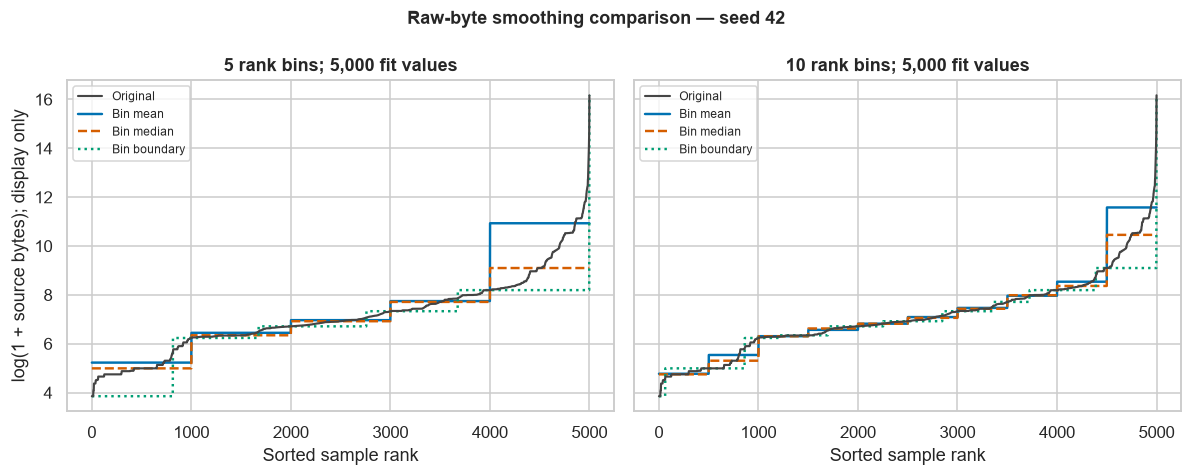

**Observed on 5,000 sampled fit values:** the least measured absolute distortion is **boundary smoothing with 10 bins (7,032.47 bytes)**. Changing from 5 to 10 bins changes mean-smoothing distortion by **-1,658.45 bytes**. The plot shows the original curve replaced by a few levels; these replacements flatten within-bin variation. For example, the largest sampled value is **10,508,068 bytes**; in its 10-bin group, mean smoothing replaces it with **106,585.28 bytes** and median smoothing with **34,710.00 bytes**, while nearest-boundary smoothing preserves this upper endpoint. A smaller reconstruction distortion is not evidence of better intrusion classification. Row order/identity, complete bin membership, group sizes and all three calculations passed their checks.

In [7]:
def rank_bin_smoothing(values, number_of_bins):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
        raise ValueError('Expected a nonempty finite one-dimensional array')
    if not isinstance(number_of_bins, (int, np.integer)) or not 1 <= number_of_bins <= len(values):
        raise ValueError('The number of bins must be an integer between 1 and n')
    order = np.argsort(values, kind='stable')
    groups = np.array_split(order, number_of_bins)
    rows = pd.DataFrame({'sample_position': np.arange(len(values)), 'original': values,
                         'bin': np.zeros(len(values), dtype=int),
                         'mean': np.nan, 'median': np.nan, 'boundary': np.nan})
    summaries = []
    rank_start = 1
    for bin_number, positions in enumerate(groups, start=1):
        current = values[positions]
        lo, hi = float(current.min()), float(current.max())
        mean, median = float(current.mean()), float(np.median(current))
        boundary = np.where(np.abs(current-lo) <= np.abs(current-hi), lo, hi)
        rows.loc[positions, 'bin'] = bin_number
        rows.loc[positions, 'mean'] = mean
        rows.loc[positions, 'median'] = median
        rows.loc[positions, 'boundary'] = boundary
        summaries.append({'bins': number_of_bins, 'bin': bin_number,
                          'sorted_ranks': f'{rank_start}–{rank_start+len(positions)-1}',
                          'n': len(current), 'lower_bytes': lo, 'upper_bytes': hi,
                          'mean_bytes': mean, 'median_bytes': median})
        rank_start += len(positions)
    summary = pd.DataFrame(summaries)
    # Independent checks of the partition and calculations, retaining input order.
    assert np.array_equal(np.sort(np.concatenate(groups)), np.arange(len(values)))
    assert summary.n.sum() == len(values) and summary.n.max()-summary.n.min() <= 1
    assert len(rows) == len(values) and np.array_equal(rows.original.to_numpy(), values)
    assert np.array_equal(rows.sample_position, np.arange(len(values)))
    for record in summary.itertuples(index=False):
        positions = order[sum(summary.n.iloc[:record.bin-1]):sum(summary.n.iloc[:record.bin])]
        selected = rows.loc[positions]
        actual = values[positions]
        assert selected.bin.eq(record.bin).all()
        assert selected.original.between(record.lower_bytes, record.upper_bytes).all()
        assert np.allclose(selected['mean'], np.mean(actual))
        assert np.allclose(selected['median'], np.median(actual))
        lower_distance = np.abs(actual-actual.min())
        upper_distance = np.abs(actual-actual.max())
        expected_boundary = np.where(lower_distance <= upper_distance, actual.min(), actual.max())
        assert np.array_equal(selected.boundary.to_numpy(), expected_boundary)
    assert np.isfinite(rows.to_numpy()).all()
    return rows, summary

# Midpoint ties, repeated values and uneven groups are checked separately from traffic data.
toy_rows, _ = rank_bin_smoothing([0, 2, 4, 8, 10, 12], 2)
assert toy_rows.loc[1, 'boundary'] == 0 and toy_rows.loc[4, 'boundary'] == 8
tie_rows, tie_summary = rank_bin_smoothing([0, 0, 0, 0, 1, 1, 1, 2, 2, 3, 4], 5)
assert tie_summary.n.max()-tie_summary.n.min() == 1
constant_rows, _ = rank_bin_smoothing([7]*10, 5)
assert constant_rows[['original', 'mean', 'median', 'boundary']].eq(7).all().all()

smoothing_sample = X_fit['sbytes'].dropna().sample(n=min(5000, X_fit['sbytes'].notna().sum()), random_state=SEED)
assert len(smoothing_sample) <= 5000 and smoothing_sample.index.is_unique
assert smoothing_sample.index.isin(X_fit.index).all()
assert smoothing_sample.index.equals(X_fit['sbytes'].dropna().sample(n=len(smoothing_sample), random_state=SEED).index)
smoothing_rows, smoothing_summaries, distortion_records, smoothing_examples = {}, [], [], []
for number_of_bins in [5, 10]:
    rows, summary = rank_bin_smoothing(smoothing_sample.to_numpy(), number_of_bins)
    rows.insert(1, 'fit_row_index', smoothing_sample.index.to_numpy())
    assert np.array_equal(rows.fit_row_index.to_numpy(), smoothing_sample.index.to_numpy())
    smoothing_rows[number_of_bins] = rows
    smoothing_summaries.append(summary)
    for method in ['mean', 'median', 'boundary']:
        distortion_records.append({'bins': number_of_bins, 'method': method, 'n': len(rows),
                                   'mean_absolute_distortion_bytes': float(np.abs(rows.original-rows[method]).mean())})
    order = np.argsort(rows.original.to_numpy(), kind='stable')
    example_positions = order[np.rint(np.array([0, .25, .5, .75, .95, 1])*(len(rows)-1)).astype(int)]
    example = rows.iloc[example_positions].copy()
    example.insert(0, 'bins', number_of_bins)
    smoothing_examples.append(example)
smoothing_bin_summary = pd.concat(smoothing_summaries, ignore_index=True)
distortion_results = pd.DataFrame(distortion_records)
display(smoothing_bin_summary.round(2))
display(pd.concat(smoothing_examples, ignore_index=True).round(2))
display(distortion_results.round(2))
assert distortion_results.n.eq(len(smoothing_sample)).all()
assert distortion_results.mean_absolute_distortion_bytes.ge(0).all()
# A median minimizes absolute error among single-value replacements for each fixed group.
for number_of_bins in [5, 10]:
    distortions = distortion_results.query('bins == @number_of_bins').set_index('method').mean_absolute_distortion_bytes
    assert distortions['median'] <= distortions['mean'] + 1e-8

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
method_colours = {'mean': '#0072B2', 'median': '#D55E00', 'boundary': '#009E73'}
method_styles = {'mean': '-', 'median': '--', 'boundary': ':'}
for ax, number_of_bins in zip(axes, [5, 10]):
    ordered = smoothing_rows[number_of_bins].sort_values('original', kind='stable')
    ranks = np.arange(1, len(ordered)+1)
    ax.plot(ranks, np.log1p(ordered.original), color='#444444', lw=1.4, label='Original', zorder=4)
    for method in ['mean', 'median', 'boundary']:
        ax.plot(ranks, np.log1p(ordered[method]), color=method_colours[method],
                linestyle=method_styles[method], lw=1.6, label=f'Bin {method}')
    ax.set(title=f'{number_of_bins} rank bins; {len(ordered):,} fit values', xlabel='Sorted sample rank')
    ax.legend(fontsize=8, loc='upper left')
axes[0].set_ylabel('log(1 + source bytes); display only')
fig.suptitle(f'Raw-byte smoothing comparison — seed {SEED}', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()
least_distortion = distortion_results.sort_values(['mean_absolute_distortion_bytes', 'bins', 'method']).iloc[0]
largest_row = smoothing_rows[10].loc[smoothing_rows[10].original.idxmax()]
distortion_by_bins = distortion_results.pivot(index='method', columns='bins', values='mean_absolute_distortion_bytes')
mean_change = distortion_by_bins.loc['mean', 10]-distortion_by_bins.loc['mean', 5]
display(Markdown(
    f'**Observed on {len(smoothing_sample):,} sampled fit values:** the least measured absolute distortion is '
    f'**{least_distortion.method} smoothing with {int(least_distortion.bins)} bins '
    f'({least_distortion.mean_absolute_distortion_bytes:,.2f} bytes)**. '
    f'Changing from 5 to 10 bins changes mean-smoothing distortion by **{mean_change:+,.2f} bytes**. '
    'The plot shows the original curve replaced by a few levels; these replacements flatten within-bin variation. '
    f'For example, the largest sampled value is **{largest_row.original:,.0f} bytes**; in its 10-bin group, '
    f'mean smoothing replaces it with **{largest_row["mean"]:,.2f} bytes** and median smoothing with '
    f'**{largest_row["median"]:,.2f} bytes**, while nearest-boundary smoothing preserves this upper endpoint. '
    'A smaller reconstruction distortion is not evidence of better intrusion classification. '
    'Row order/identity, complete bin membership, group sizes and all three calculations passed their checks.'))
smoothing_demo_checked = True

### 4.4 Training-fit outlier and skewness diagnostics

For `dur`, `sbytes`, `dbytes` and `rate`, calculate $IQR=Q_3-Q_1$ and fences $[Q_1-1.5IQR,\ Q_3+1.5IQR]$ using nonmissing **training-fit** values. Flag values strictly outside the fences; the percentage denominator is the valid count for that feature. Skewness is pandas' sample skewness (adjusted Fisher–Pearson); it is calculated on the actual raw and `log1p` values, without clipping or normalization first.

An IQR flag is a distribution diagnostic, **not proof of an error**. All valid extremes are retained. A log transform can change shape substantially, but it does **not always reduce absolute skewness**. The observed comparison is reported below; none of these diagnostics changes the cleaning policy or selects classifier settings.

In [8]:
iqr_skew_records = []
for feature in ['dur', 'sbytes', 'dbytes', 'rate']:
    values = X_fit[feature].dropna()
    assert len(values) >= 3 and values.ge(0).all() and np.isfinite(values).all()
    q1, q3 = values.quantile([.25, .75])
    iqr = float(q3-q1)
    lower, upper = float(q1-1.5*iqr), float(q3+1.5*iqr)
    flags = (values < lower) | (values > upper)
    raw_skew, log_skew = float(values.skew()), float(np.log1p(values).skew())
    iqr_skew_records.append({'feature': feature, 'valid_n': len(values), 'IQR': iqr,
                             'lower_fence': lower, 'upper_fence': upper,
                             'flagged_n': int(flags.sum()), 'flagged_pct': 100*flags.mean(),
                             'raw_skew': raw_skew, 'log1p_skew': log_skew,
                             'absolute_skew_reduced': abs(log_skew) < abs(raw_skew)})
    assert len(values) == X_fit[feature].notna().sum()
    assert int(flags.sum()) == int(np.count_nonzero((values.to_numpy() < lower) | (values.to_numpy() > upper)))
iqr_skew_results = pd.DataFrame(iqr_skew_records).set_index('feature')
assert np.isfinite(iqr_skew_results.select_dtypes(include=np.number).to_numpy()).all()
assert iqr_skew_results.flagged_pct.between(0, 100).all()
display(iqr_skew_results.round(4))
largest_flag = iqr_skew_results.sort_values('flagged_pct', ascending=False).iloc[0]
reduced_features = iqr_skew_results.index[iqr_skew_results.absolute_skew_reduced].tolist()
other_features = iqr_skew_results.index[~iqr_skew_results.absolute_skew_reduced].tolist()
skew_observation = (f'Absolute skewness decreased for **{", ".join(reduced_features)}**. ' if reduced_features else
                    'None of these features had a decrease in absolute skewness. ')
if other_features:
    skew_observation += f'It did not decrease for **{", ".join(other_features)}**. '
else:
    skew_observation += 'All four decreased in this run; that observed result is not a universal guarantee. '
display(Markdown(
    f'**Observed:** **{largest_flag.name}** has the largest flagged share '
    f'(**{largest_flag.flagged_pct:.2f}%**, {int(largest_flag.flagged_n):,} of {int(largest_flag.valid_n):,} values). '
    + skew_observation + 'Flags may represent legitimate bursts, long flows or attack behaviour. '
    'No flagged row was removed or capped.'))
assert all(frame_fingerprint(frame) == refinement_before[name] for name, frame in refinement_frames.items())
iqr_skew_demo_checked = True
print('PASS: descriptive/preprocessing demonstrations left training, validation, test and mining inputs unchanged.')

,valid_n,IQR,lower_fence,upper_fence,flagged_n,flagged_pct,raw_skew,log1p_skew,absolute_skew_reduced
feature,,,,,,,,,
dur,79685,0.9987,-1.4919,2.5030,5687,7.1369,9.0503,2.6467,True
sbytes,79685,2390.0000,-3041.0000,6519.0000,9508,11.9320,34.5235,0.8940,True
dbytes,79685,3112.0000,-4400.0000,8048.0000,16153,20.2711,31.2261,-0.5205,True
rate,79685,2909.7804,-4339.0302,7300.0914,10957,13.7504,6.4640,0.7676,True


**Observed:** **dbytes** has the largest flagged share (**20.27%**, 16,153 of 79,685 values). Absolute skewness decreased for **dur, sbytes, dbytes, rate**. All four decreased in this run; that observed result is not a universal guarantee. Flags may represent legitimate bursts, long flows or attack behaviour. No flagged row was removed or capped.

PASS: descriptive/preprocessing demonstrations left training, validation, test and mining inputs unchanged.


## 5. Interpretable traffic transactions

We choose eight traffic attributes for pattern mining: protocol, service, state, duration, source bytes, destination bytes, source-service connection count and source TTL. These cover connection type, size, duration and repetition without exploding the item universe. Each flow contributes one `feature=value` item per feature. Numerical cut points use training quartiles, with repeated cut points merged; bounds are ±∞ so extreme valid values still receive a bin. Missing values receive a separate item.

The main sample is 5,000 uniformly sampled eligible training flows, seed 42. Runtime subsets are nested prefixes of the same shuffled sample. Binning uses only training data. Neither `attack_cat` nor `label` appears in the primary transactions. A later, clearly separate descriptive analysis adds the binary label only as a rule consequent.

In [9]:
MINE_CAT = ['proto', 'service', 'state']
MINE_NUM = ['dur', 'sbytes', 'dbytes', 'ct_srv_src', 'sttl']
MINE_FEATURES = MINE_CAT + MINE_NUM
MAX_LEN = 3
MAIN_N = min(5000, len(train))
mining_sample = train.sample(MAIN_N, random_state=SEED).reset_index(drop=True)
bin_edges = {}
bin_records = []
for c in MINE_NUM:
    values = train[c].dropna().to_numpy(dtype=float)
    interior = np.unique(np.quantile(values, [.25, .5, .75]))
    # Do not create an empty lowest bin when a quantile equals the minimum.
    interior = interior[(interior > values.min()) & (interior < values.max())]
    edges = np.r_[-np.inf, interior, np.inf]
    bin_edges[c] = edges
    for j in range(len(edges) - 1):
        bin_records.append({'feature': c, 'item': f'{c}=B{j+1}',
                            'training-derived interval': f'({edges[j]:.6g}, {edges[j+1]:.6g}]'})
display(pd.DataFrame(bin_records))

def make_transactions(frame, include_label=False):
    items = pd.DataFrame(index=frame.index)
    for c in MINE_CAT:
        items[c] = c + '=' + frame[c].fillna('<missing>').astype(str)
    for c in MINE_NUM:
        ids = pd.cut(frame[c], bins=bin_edges[c], labels=False, right=True)
        items[c] = [f'{c}=<missing>' if pd.isna(v) else f'{c}=B{int(v)+1}' for v in ids]
    if include_label:
        items['descriptive_label'] = frame['label'].map({0: 'label=normal', 1: 'label=attack'})
    return [frozenset(row) for row in items.itertuples(index=False, name=None)]

transactions = make_transactions(mining_sample)
assert all(len(t) == len(MINE_FEATURES) for t in transactions)
assert not any(item.startswith(('id=', 'attack_cat=', 'label=')) for t in transactions for item in t)
universe = sorted(set().union(*transactions))
print(f'Main training sample: {len(transactions):,} transactions; {len(MINE_FEATURES)} selected features; '
      f'{len(universe)} distinct items; maximum length {MAX_LEN}.')
display(pd.DataFrame({'sample_transaction': ['; '.join(sorted(t)) for t in transactions[:4]]}))

,feature,item,training-derived interval
0,dur,dur=B1,"(-inf, 0.0062005]"
1,dur,dur=B2,"(0.0062005, 0.387509]"
2,dur,dur=B3,"(0.387509, 1.00557]"
3,dur,dur=B4,"(1.00557, inf]"
4,sbytes,sbytes=B1,"(-inf, 546]"
...,...,...,...
14,ct_srv_src,ct_srv_src=B3,"(6, inf]"
15,sttl,sttl=B1,"(-inf, 31]"
16,sttl,sttl=B2,"(31, 62]"
17,sttl,sttl=B3,"(62, 254]"


Main training sample: 5,000 transactions; 8 selected features; 79 distinct items; maximum length 3.


,sample_transaction
0,ct_srv_src=B1; dbytes=B4; dur=B2; proto=tcp; sbytes=B1; service=ftp-data; state=FIN; sttl=B1
1,ct_srv_src=B1; dbytes=B4; dur=B4; proto=tcp; sbytes=B3; service=http; state=FIN; sttl=B2
2,ct_srv_src=B1; dbytes=B1; dur=B1; proto=udp; sbytes=B1; service=dns; state=CON; sttl=B1
3,ct_srv_src=B1; dbytes=B1; dur=B3; proto=tcp; sbytes=B1; service=-; state=FIN; sttl=B3


## 6. Five frequent-itemset methods and correctness

An itemset's support is its transaction count divided by the number of transactions. A set is frequent when its count is at least `ceil(min_support × n)`. The same transaction sets, threshold and length limit are passed to every method.

| Method | Actual mechanism here |
|---|---|
| Apriori | mlxtend's level-wise candidate generation and anti-monotone pruning |
| FP-Growth | mlxtend's FP-tree and conditional pattern mining |
| Hash-based Apriori | Implemented first-pass pair hashing; low-count buckets prune pair candidates before exact counting, then Apriori joins/pruning for longer sets. This is the hash-pruning variant, not a claim to implement full DHP transaction pruning. |
| Dynamic Itemset Counting (DIC) | Implemented circular scan with stations, dashed/solid and circle/box states. Candidates can enter at intermediate stations once all immediate subsets are boxes; each candidate is counted through exactly one complete database cycle from its start. |
| Vertical TID / ECLAT style | Implemented vertical transaction-ID sets and recursive prefix extensions using set intersections |

Apriori uses the fact that every subset of a frequent set is frequent. DIC's partial counts that already reach the full support threshold safely identify eventual frequent subsets. Hash buckets are upper bounds: collisions can reduce pruning effectiveness but do not cause false negatives. These educational Python implementations prioritize transparent mechanisms; timings are not a comparison of equally optimized software.

In [10]:
def minimum_count(n, support):
    if n <= 0 or not 0 < support <= 1:
        raise ValueError('Need nonempty transactions and 0 < support <= 1')
    return math.ceil(support * n - 1e-12)

def level_candidates(previous, length):
    previous = set(previous)
    ordered = sorted(tuple(sorted(s)) for s in previous)
    result = set()
    for a, b in combinations(ordered, 2):
        if a[:-1] != b[:-1]:
            continue
        joined = frozenset(a) | frozenset(b)
        if len(joined) == length and all(frozenset(s) in previous for s in combinations(sorted(joined), length-1)):
            result.add(joined)
    return result

def library_miner(tx, support, max_len, method):
    minimum_count(len(tx), support)
    if not set().union(*tx):
        return {}
    encoder = TransactionEncoder()
    matrix = pd.DataFrame(encoder.fit(tx).transform(tx), columns=encoder.columns_, dtype=bool)
    result = method(matrix, min_support=support, use_colnames=True, max_len=max_len)
    return {frozenset(row.itemsets): int(round(row.support * len(tx))) for row in result.itertuples()}

def hash_apriori(tx, support, max_len=3, bucket_count=4099, diagnostics=False):
    n, threshold = len(tx), minimum_count(len(tx), support)
    ordered = [tuple(sorted(set(t))) for t in tx]
    all_items = sorted(set().union(*tx))
    item_ids = {item: j+1 for j, item in enumerate(all_items)}
    buckets = np.zeros(bucket_count, dtype=np.int64)
    def pair_bucket(pair):
        a, b = sorted(item_ids[item] for item in pair)
        return (a * 131 + b * 17) % bucket_count
    singles = Counter()
    for t in ordered:                         # First pass: singles AND hash bucket counts.
        singles.update(t)
        if max_len >= 2:
            for pair in combinations(t, 2):
                buckets[pair_bucket(pair)] += 1
    level = {frozenset([item]) for item, count in singles.items() if count >= threshold}
    frequent = {s: singles[next(iter(s))] for s in level}
    diag = {'pair_candidates_before_hash': 0, 'pair_candidates_after_hash': 0,
            'full_scans': 1, 'hash_buckets': bucket_count}
    frequent_items = set().union(*level) if level else set()
    reduced = [tuple(item for item in t if item in frequent_items) for t in ordered]
    for length in range(2, max_len+1):
        candidates = level_candidates(level, length)
        if length == 2:
            diag['pair_candidates_before_hash'] = len(candidates)
            candidates = {s for s in candidates if buckets[pair_bucket(s)] >= threshold}
            diag['pair_candidates_after_hash'] = len(candidates)
        if not candidates:
            break
        counts = Counter()
        for t in reduced:
            for combo in combinations(t, length):
                key = frozenset(combo)
                if key in candidates:
                    counts[key] += 1
        diag['full_scans'] += 1
        level = {s for s in candidates if counts[s] >= threshold}
        frequent.update({s: counts[s] for s in level})
        if not level:
            break
    return (frequent, diag) if diagnostics else frequent

def dynamic_itemset_counting(tx, support, max_len=3, station_size=256, diagnostics=False):
    n, threshold = len(tx), minimum_count(len(tx), support)
    if station_size < 1:
        raise ValueError('station_size must be positive')
    ordered = [tuple(sorted(set(t))) for t in tx]
    items = sorted(set().union(*tx))
    # DC= dashed circle, DB= dashed box, SC= solid circle, SB= solid box.
    records = {frozenset([i]): {'count': 0, 'seen': 0, 'state': 'DC', 'started': 0} for i in items}
    cursor, stations, early_insertions = 0, 0, 0
    while True:
        active = {s for s, r in records.items() if r['state'].startswith('D')}
        if not active:
            break
        # Shorter boundary if necessary: never count a candidate beyond one full cycle.
        step = min(station_size, min(n-records[s]['seen'] for s in active))
        active_lengths = sorted({len(s) for s in active})
        for offset in range(step):
            t = ordered[(cursor + offset) % n]
            for length in active_lengths:
                for combo in combinations(t, length):
                    key = frozenset(combo)
                    if key in active:
                        records[key]['count'] += 1
        cursor += step
        stations += 1
        for s in active:
            r = records[s]
            r['seen'] += step
            box = r['count'] >= threshold
            r['state'] = ('S' if r['seen'] == n else 'D') + ('B' if box else 'C')
        # Include BOTH suspected frequent (DB) and confirmed frequent (SB) subsets.
        boxes = {s for s, r in records.items() if r['state'].endswith('B')}
        for length in range(2, max_len+1):
            previous = {s for s in boxes if len(s) == length-1}
            for candidate in level_candidates(previous, length):
                if candidate not in records:
                    records[candidate] = {'count': 0, 'seen': 0, 'state': 'DC', 'started': cursor}
                    early_insertions += int(cursor < n)
        assert cursor <= (max_len+1)*n, 'DIC did not terminate in the expected bounded number of cycles'
    assert all(r['seen'] == n for r in records.values())
    frequent = {s: r['count'] for s, r in records.items() if r['state'] == 'SB'}
    diag = {'stations': stations, 'transaction_reads': cursor, 'equivalent_full_scans': cursor/n,
            'candidates_added_before_first_lap': early_insertions,
            'final_states': dict(Counter(r['state'] for r in records.values())),
            'station_size': station_size}
    return (frequent, diag) if diagnostics else frequent

def vertical_tid_mining(tx, support, max_len=3):
    threshold = minimum_count(len(tx), support)
    tids = defaultdict(set)
    for tid, t in enumerate(tx):
        for item in set(t):
            tids[item].add(tid)
    suffixes = [(item, tids[item]) for item in sorted(tids) if len(tids[item]) >= threshold]
    frequent = {}
    def extend(prefix, suffixes):
        for j, (item, item_tids) in enumerate(suffixes):
            current = prefix + (item,)
            frequent[frozenset(current)] = len(item_tids)
            if len(current) < max_len:
                intersections = []
                for other, other_tids in suffixes[j+1:]:
                    common = item_tids & other_tids
                    if len(common) >= threshold:
                        intersections.append((other, common))
                extend(current, intersections)
    extend((), suffixes)
    return frequent

MINERS = {
    'Apriori': lambda tx, s, k: library_miner(tx, s, k, library_apriori),
    'FP-Growth': lambda tx, s, k: library_miner(tx, s, k, library_fpgrowth),
    'Hash Apriori': lambda tx, s, k: hash_apriori(tx, s, k),
    'DIC': lambda tx, s, k: dynamic_itemset_counting(tx, s, k),
    'Vertical TID': lambda tx, s, k: vertical_tid_mining(tx, s, k)}

def brute_force(tx, support, max_len=3):
    threshold = minimum_count(len(tx), support)
    items = sorted(set().union(*tx))
    result = {}
    for length in range(1, max_len+1):
        for combo in combinations(items, length):
            key = frozenset(combo)
            count = sum(key <= t for t in tx)
            if count >= threshold:
                result[key] = count
    return result

def assert_equal_counts(actual, expected, context):
    if actual != expected:
        missing = set(expected) - set(actual)
        extra = set(actual) - set(expected)
        wrong = {s: (actual[s], expected[s]) for s in set(actual) & set(expected) if actual[s] != expected[s]}
        raise AssertionError(f'{context}: missing={missing}; extra={extra}; wrong={wrong}')

toy = [frozenset(x) for x in ['ACD', 'BCE', 'ABCE', 'BE']]
expected_toy = {frozenset('B'): 3, frozenset('C'): 3, frozenset('E'): 3, frozenset('BE'): 3}
assert brute_force(toy, .75, 3) == expected_toy
tiny_cases = [toy, [frozenset(), frozenset('A'), frozenset('AB'), frozenset('AB')],
              [frozenset('ABC')]*5, [frozenset()]*4]
test_rng = np.random.default_rng(SEED)
for _ in range(10):
    tiny_cases.append([frozenset(item for item in 'ABCDEF' if test_rng.random() < .5) for _ in range(13)])
correctness_checks = 0
for case_no, tiny in enumerate(tiny_cases):
    for support in [.20, .30, .40, .75, 1.0]:
        expected = brute_force(tiny, support, 3)
        for name, miner in MINERS.items():
            assert_equal_counts(miner(tiny, support, 3), expected, f'tiny {case_no}, {name}, {support}')
            correctness_checks += 1
        for station_size in [1, 2, 7]:
            assert_equal_counts(dynamic_itemset_counting(tiny, support, 3, station_size=station_size),
                                expected, f'DIC station {station_size}, tiny {case_no}')
            correctness_checks += 1

# A bounded real-data projection makes independent exhaustive enumeration affordable.
common_items = {item for item, count in Counter(i for t in transactions[:300] for i in t).most_common(12)}
real_tiny = [t & common_items for t in transactions[:300]]
for support in [.20, .30, .40]:
    expected = brute_force(real_tiny, support, 3)
    for name, miner in MINERS.items():
        assert_equal_counts(miner(real_tiny, support, 3), expected, f'projected real data, {name}, {support}')
        correctness_checks += 1
bounded_real_checks = 0
for support in [.20, .30, .40]:
    reference = MINERS['Apriori'](transactions[:1000], support, MAX_LEN)
    for name, miner in MINERS.items():
        assert_equal_counts(miner(transactions[:1000], support, MAX_LEN), reference, f'real 1000, {name}')
        bounded_real_checks += 1
_, dic_demo = dynamic_itemset_counting(toy, .50, 3, station_size=1, diagnostics=True)
assert dic_demo['candidates_added_before_first_lap'] > 0  # Actual intermediate-station insertion.
_, hash_demo = hash_apriori(toy, .75, 3, diagnostics=True)
assert hash_demo['pair_candidates_after_hash'] < hash_demo['pair_candidates_before_hash']
print(f'PASS: {correctness_checks} comparisons against brute force; {bounded_real_checks} full-feature real-data comparisons.')
print('Toy supports at .75:', {''.join(sorted(k)): v for k, v in expected_toy.items()})
print('Mechanism evidence: DIC', dic_demo, '| hash pruning', hash_demo)

PASS: 575 comparisons against brute force; 15 full-feature real-data comparisons.
Toy supports at .75: {'B': 3, 'C': 3, 'E': 3, 'BE': 3}
Mechanism evidence: DIC {'stations': 11, 'transaction_reads': 11, 'equivalent_full_scans': 2.75, 'candidates_added_before_first_lap': 6, 'final_states': {'SB': 9, 'SC': 3}, 'station_size': 1} | hash pruning {'pair_candidates_before_hash': 3, 'pair_candidates_after_hash': 1, 'full_scans': 2, 'hash_buckets': 4099}


## 7. Pattern experiments, rules and measured scaling

Primary support values are **0.20, 0.30 and 0.40**, with maximum itemset length **3**. All five methods must return identical sets and integer counts. We then generate rules at confidence **0.70, 0.80 and 0.90** for each support. For `A → B`, support is `P(A∪B)`, confidence is `P(B|A)` and lift is `P(B|A)/P(B)`. Lift above 1 indicates positive association, not causation or a validated detector.

Closed means there is no proper frequent superset with the same count; maximal means there is no proper frequent superset. The flags below are **relative to the searched length bound ≤3**. In particular, a length-3 set can have an unseen frequent length-4 extension, so these are not unrestricted closed/maximal claims.

In [11]:
SUPPORTS, CONFIDENCES = [.20, .30, .40], [.70, .80, .90]
pattern_runs, frequent_by_support = [], {}
for support in SUPPORTS:
    reference = None
    for name, miner in MINERS.items():
        start = time.perf_counter()
        found = miner(transactions, support, MAX_LEN)
        elapsed = time.perf_counter() - start
        if reference is None:
            reference = found
        assert_equal_counts(found, reference, f'main sample {name}, support {support}')
        pattern_runs.append({'algorithm': name, 'n': len(transactions), 'features': len(MINE_FEATURES),
                             'distinct_items': len(universe), 'support': support,
                             'min_count': minimum_count(len(transactions), support),
                             'max_length': MAX_LEN, 'frequent_itemsets': len(found), 'seconds': elapsed})
    frequent_by_support[support] = reference
pattern_results = pd.DataFrame(pattern_runs)
display(pattern_results.round({'seconds': 4}))
print('All main-sample support counts match exactly across the five implementations.')

def itemset_table(counts, n):
    rows = []
    for key, count in counts.items():
        supersets = [s for s in counts if key < s]
        rows.append({'itemset': '; '.join(sorted(key)), 'length': len(key), 'count': count,
                     'support': count/n, 'closed_within_bound': not any(counts[s] == count for s in supersets),
                     'maximal_within_bound': not bool(supersets)})
    return pd.DataFrame(rows).sort_values(['length', 'support', 'itemset'], ascending=[True, False, True])

main_itemsets = itemset_table(frequent_by_support[.20], len(transactions))
print('Selected frequent sets (up to 6 from each length), including closed/maximal flags:')
display(main_itemsets.groupby('length', group_keys=False).head(6).round({'support': 4}))
display(main_itemsets.groupby('length').agg(itemsets=('itemset', 'size'),
                                           closed_within_bound=('closed_within_bound', 'sum'),
                                           maximal_within_bound=('maximal_within_bound', 'sum')))

RULE_COLUMNS = ['antecedent', 'consequent', 'support', 'confidence', 'lift', 'count', 'consequent_size']
def generate_rules(counts, n, minimum_confidence):
    rows = []
    for union, union_count in counts.items():
        if len(union) < 2:
            continue
        for length in range(1, len(union)):
            for combo in combinations(sorted(union), length):
                antecedent = frozenset(combo)
                consequent = union - antecedent
                confidence = union_count/counts[antecedent]
                if confidence + 1e-12 >= minimum_confidence:
                    rows.append({'antecedent': '; '.join(sorted(antecedent)),
                                 'consequent': '; '.join(sorted(consequent)), 'support': union_count/n,
                                 'confidence': confidence, 'lift': confidence/(counts[consequent]/n),
                                 'count': union_count, 'consequent_size': len(consequent)})
    return pd.DataFrame(rows, columns=RULE_COLUMNS)

rule_grid = []
rule_sets = {}
for support, counts in frequent_by_support.items():
    for confidence in CONFIDENCES:
        rules = generate_rules(counts, len(transactions), confidence)
        rule_sets[support, confidence] = rules
        rule_grid.append({'support': support, 'confidence': confidence, 'itemsets': len(counts),
                          'all_rules': len(rules), 'positive_lift_rules': int((rules['lift'] > 1.05).sum())})
display(pd.DataFrame(rule_grid))
useful_rules = rule_sets[.20, .80].query('lift > 1.05 and consequent_size == 1').sort_values(
    ['lift', 'confidence', 'support'], ascending=False)
print('Selected primary traffic rules: confidence ≥.80, lift >1.05, single-item consequent.')
display(useful_rules.drop_duplicates('consequent').head(10).round({'support': 4, 'confidence': 4, 'lift': 3}))

# Supplementary experiment, explicitly distinct from the faculty's primary support grid.
LOW_SUPPORT = .05
low_sets = MINERS['FP-Growth'](transactions, LOW_SUPPORT, MAX_LEN)
low_rules = generate_rules(low_sets, len(transactions), .80).query('lift > 1.05 and consequent_size == 1')
print(f'Supplementary LOWER-support traffic experiment: support={LOW_SUPPORT}, confidence=.80, n={len(transactions)}, max_length=3.')
print(f'{len(low_sets)} frequent sets; {len(low_rules)} positive-lift, single-consequent rules.')
display(low_rules.sort_values(['lift', 'support'], ascending=False).drop_duplicates('consequent').head(8).round(4))

label_transactions = make_transactions(mining_sample, include_label=True)
label_sets = MINERS['FP-Growth'](label_transactions, LOW_SUPPORT, MAX_LEN)
label_rules = generate_rules(label_sets, len(label_transactions), .80)
label_rules = label_rules[(label_rules.consequent == 'label=attack') & ~label_rules.antecedent.str.contains('label=')]
print('Separate descriptive attack-consequent rules: training sample only, support=.05, confidence=.80.')
display(label_rules.sort_values(['lift', 'support'], ascending=False).head(10).round(4))
_, hash_main_diag = hash_apriori(transactions, .20, MAX_LEN, diagnostics=True)
_, dic_main_diag = dynamic_itemset_counting(transactions, .20, MAX_LEN, diagnostics=True)
print('Main mechanism diagnostics:', hash_main_diag, dic_main_diag)

# Verify independently computed rule arithmetic on a chosen real training rule.
if not useful_rules.empty:
    chosen = useful_rules.iloc[0]
    antecedent = frozenset(chosen.antecedent.split('; '))
    consequent = frozenset(chosen.consequent.split('; '))
    joint_count = sum(antecedent | consequent <= t for t in transactions)
    antecedent_count = sum(antecedent <= t for t in transactions)
    consequent_count = sum(consequent <= t for t in transactions)
    assert np.isclose(chosen.support, joint_count/len(transactions))
    assert np.isclose(chosen.confidence, joint_count/antecedent_count)
    assert np.isclose(chosen.lift, (joint_count/antecedent_count)/(consequent_count/len(transactions)))
    display(Markdown(f'Example interpretation: **{chosen.antecedent} → {chosen.consequent}** appears in '
                     f'**{chosen.support:.1%}** of sampled flows. Among flows matching its antecedent, '
                     f'**{chosen.confidence:.1%}** match the consequent, **{chosen.lift:.2f}×** its overall frequency.'))

,algorithm,n,features,distinct_items,support,min_count,max_length,frequent_itemsets,seconds
0,Apriori,5000,8,79,0.2,1000,3,66,0.0114
1,FP-Growth,5000,8,79,0.2,1000,3,66,0.0268
2,Hash Apriori,5000,8,79,0.2,1000,3,66,0.1804
3,DIC,5000,8,79,0.2,1000,3,66,0.1638
4,Vertical TID,5000,8,79,0.2,1000,3,66,0.0109
5,Apriori,5000,8,79,0.3,1500,3,18,0.0095
6,FP-Growth,5000,8,79,0.3,1500,3,18,0.0226
7,Hash Apriori,5000,8,79,0.3,1500,3,18,0.1530
8,DIC,5000,8,79,0.3,1500,3,18,0.1138
9,Vertical TID,5000,8,79,0.3,1500,3,18,0.0076


All main-sample support counts match exactly across the five implementations.
Selected frequent sets (up to 6 from each length), including closed/maximal flags:


,itemset,length,count,support,closed_within_bound,maximal_within_bound
10,proto=tcp,1,3789,0.7578,True,False
17,state=FIN,1,3704,0.7408,False,False
16,service=-,1,2897,0.5794,True,False
0,ct_srv_src=B1,1,2784,0.5568,True,False
19,sttl=B3,1,2168,0.4336,True,False
18,sttl=B1,1,2036,0.4072,True,False
41,proto=tcp; state=FIN,2,3704,0.7408,True,False
20,ct_srv_src=B1; proto=tcp,2,2292,0.4584,True,False
22,ct_srv_src=B1; state=FIN,2,2272,0.4544,False,False
40,proto=tcp; service=-,2,2220,0.4440,True,False


,itemsets,closed_within_bound,maximal_within_bound
length,,,
1,20,18,2
2,32,18,6
3,14,14,14


,support,confidence,itemsets,all_rules,positive_lift_rules
0,0.2,0.7,66,71,60
1,0.2,0.8,66,55,55
2,0.2,0.9,66,45,45
3,0.3,0.7,18,18,12
4,0.3,0.8,18,11,11
5,0.3,0.9,18,8,8
6,0.4,0.7,13,12,9
7,0.4,0.8,13,9,9
8,0.4,0.9,13,6,6


...

,antecedent,consequent,support,confidence,lift,count,consequent_size
243,dbytes=B1; sttl=B1,service=dns,0.0740,0.9320,8.7265,370,1
309,proto=udp; sttl=B3,state=INT,0.1062,0.9743,7.9601,531,1
188,proto=udp; sttl=B1,state=CON,0.1130,1.0000,7.8003,565,1
141,sbytes=B2; sttl=B2,service=http,0.0616,0.8280,4.6203,308,1
231,dur=B1; service=dns,proto=udp,0.1026,1.0000,4.4603,513,1
429,service=smtp,sbytes=B4,0.0506,0.9583,4.0300,253,1
234,dur=B1; service=dns,sbytes=B1,0.1026,1.0000,3.9062,513,1
247,service=dns; sttl=B1,dur=B1,0.0732,0.9892,3.7871,366,1


Separate descriptive attack-consequent rules: training sample only, support=.05, confidence=.80.


,antecedent,consequent,support,confidence,lift,count,consequent_size
216,dbytes=B4; sttl=B2,label=attack,0.0538,0.9926,2.0845,269,1
167,service=http; sttl=B3,label=attack,0.0634,0.9784,2.0546,317,1
206,dur=B4; sttl=B2,label=attack,0.0760,0.9314,1.9558,380,1
201,ct_srv_src=B1; sttl=B2,label=attack,0.1314,0.9280,1.9487,657,1
196,state=FIN; sttl=B2,label=attack,0.1356,0.9237,1.9397,678,1
174,sbytes=B2; service=http,label=attack,0.0834,0.8835,1.8553,417,1
221,dbytes=B3; sttl=B2,label=attack,0.0798,0.8808,1.8496,399,1
374,ct_srv_src=B1; sttl=B3,label=attack,0.2014,0.8681,1.8230,1007,1
184,sttl=B2,label=attack,0.1378,0.8667,1.8200,689,1
416,sbytes=B1; state=INT,label=attack,0.0746,0.8654,1.8174,373,1


Main mechanism diagnostics: {'pair_candidates_before_hash': 190, 'pair_candidates_after_hash': 32, 'full_scans': 3, 'hash_buckets': 4099} {'stations': 57, 'transaction_reads': 14352, 'equivalent_full_scans': 2.8704, 'candidates_added_before_first_lap': 173, 'final_states': {'SB': 66, 'SC': 224}, 'station_size': 256}


Example interpretation: **proto=udp → dur=B1** appears in **20.9%** of sampled flows. Among flows matching its antecedent, **93.0%** match the consequent, **3.56×** its overall frequency.

,algorithm,n,features,distinct_items,support,max_length,repeats,itemsets,median_seconds,min_seconds,max_seconds
0,Apriori,500,8,39,0.2,3,3,68,0.0027,0.0027,0.0027
1,FP-Growth,500,8,39,0.2,3,3,68,0.0044,0.0042,0.0045
2,Hash Apriori,500,8,39,0.2,3,3,68,0.0179,0.0178,0.0180
3,DIC,500,8,39,0.2,3,3,68,0.0176,0.0162,0.0178
4,Vertical TID,500,8,39,0.2,3,3,68,0.0012,0.0012,0.0012
5,Apriori,1500,8,51,0.2,3,3,67,0.0042,0.0041,0.0050
6,FP-Growth,1500,8,51,0.2,3,3,67,0.0107,0.0098,0.0118
7,Hash Apriori,1500,8,51,0.2,3,3,67,0.0520,0.0517,0.0520
8,DIC,1500,8,51,0.2,3,3,67,0.0525,0.0506,0.0525
9,Vertical TID,1500,8,51,0.2,3,3,67,0.0033,0.0033,0.0036


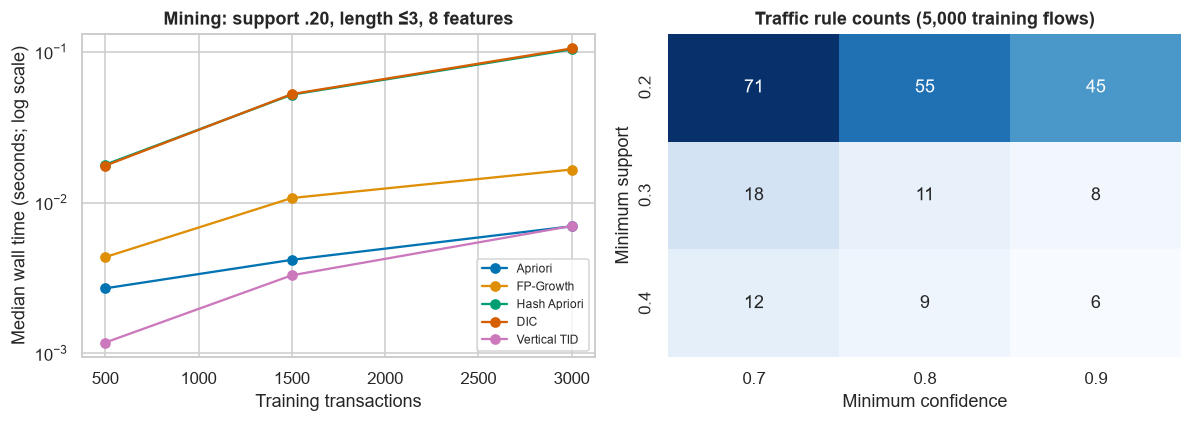

At **3,000** transactions, the smallest measured median was **Apriori (0.0070 s)**. These measurements show local behaviour on bounded transactions; three repetitions do not establish hardware-independent scalability. The table gives measured median/minimum/maximum wall times. Each timed call includes its representation construction; file I/O, discretization and rule generation are excluded. Higher support discards less-common patterns, and higher confidence retains fewer rules.

In [12]:
# End-to-end mining time includes each method's representation construction.
# It excludes file I/O, feature discretization and rule generation; no warm-cache claim is made.
runtime_records = []
for n in [500, 1500, 3000]:
    subset = transactions[:n]
    reference = MINERS['Apriori'](subset, .20, MAX_LEN)
    for name, miner in MINERS.items():
        measurements = []
        for repetition in range(3):
            start = time.perf_counter()
            found = miner(subset, .20, MAX_LEN)
            measurements.append(time.perf_counter() - start)
            assert_equal_counts(found, reference, f'runtime n={n}, {name}')
        assert len(measurements) == 3
        runtime_records.append({'algorithm': name, 'n': n, 'features': len(MINE_FEATURES),
                                'distinct_items': len(set().union(*subset)), 'support': .20,
                                'max_length': MAX_LEN, 'repeats': 3, 'itemsets': len(found),
                                'median_seconds': float(np.median(measurements)),
                                'min_seconds': min(measurements), 'max_seconds': max(measurements)})
runtime_results = pd.DataFrame(runtime_records)
assert runtime_results.repeats.eq(3).all()
assert (runtime_results.min_seconds <= runtime_results.median_seconds).all()
assert (runtime_results.median_seconds <= runtime_results.max_seconds).all()
display(runtime_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, rows in runtime_results.groupby('algorithm', sort=False):
    axes[0].plot(rows.n, rows.median_seconds, marker='o', label=name)
axes[0].set(xlabel='Training transactions', ylabel='Median wall time (seconds; log scale)',
            title='Mining: support .20, length ≤3, 8 features', yscale='log')
axes[0].legend(fontsize=8)
grid_frame = pd.DataFrame(rule_grid).pivot(index='support', columns='confidence', values='all_rules')
sns.heatmap(grid_frame, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set(title='Traffic rule counts (5,000 training flows)', xlabel='Minimum confidence', ylabel='Minimum support')
fig.tight_layout()
plt.show()
fastest = runtime_results.query('n == 3000').sort_values('median_seconds').iloc[0]
display(Markdown(f'At **3,000** transactions, the smallest measured median was **{fastest.algorithm} '
                 f'({fastest.median_seconds:.4f} s)**. These measurements show local behaviour on '
                 'bounded transactions; three repetitions do not establish hardware-independent scalability. '
                 'The table gives measured median/minimum/maximum wall times. Each timed call includes its '
                 'representation construction; file I/O, discretization and rule generation are excluded. '
                 'Higher support discards less-common patterns, and higher confidence retains fewer rules.'))

## 8. Classification concepts and validation-only model selection

**Decision trees.** Gini impurity is $1-\sum_c p_c^2$. Entropy is $-\sum_c p_c\log_2 p_c$; information gain is parent entropy minus the child-size-weighted entropy. A split seeks the largest impurity reduction. Both sklearn trees below are binary CART-style trees, one using Gini and one using entropy. The entropy tree is **not ID3 or C4.5**; gain ratio, ID3 and SLIQ are explained/listed in the slides but are not implemented here.

**Mixed Naive Bayes.** We use Gaussian likelihoods for log-transformed, normalized numerical attributes and categorical likelihoods for protocol/service/state. Given the class, features are assumed independent. This is often unrealistic for correlated traffic, but provides a fast probabilistic comparison. Additive smoothing uses $(N_{cjv}+\alpha)/(N_c+\alpha K_j)$ and reserves an extra category for previously unseen values. Gaussian variances receive a small positive floor. The two likelihood types share a single class prior. There is no Gaussian assumption for one-hot protocol indicators.

**Random Forest — beyond class.** A forest fits many trees to bootstrap samples, considers a random subset of features at each split, and averages their attack probabilities. This reduces tree variance, at greater training cost. Our explicit forest experiment uses 64 trees and two workers; it is an implemented additional concept, not an extension proposal.

All candidates fit preprocessing on the training-fit portion. Four candidates per learned model vary tree depth/leaf size, or Naive Bayes smoothing. **Validation macro F1** is the selection objective, with validation ROC-AUC breaking score ties and fixed grid order as the last tie-break. The overall chosen model is fixed before test evaluation. Each selected family is then refitted using all eligible training rows. We do not optimize a test threshold; predictions use the estimator's fixed default class decision.

In [13]:
class MixedNaiveBayes(ClassifierMixin, BaseEstimator):
    """Gaussian numeric + categorical likelihoods with one prior and explicit smoothing."""
    def __init__(self, alpha=1.0, var_smoothing=1e-4):
        self.alpha = alpha
        self.var_smoothing = var_smoothing
    def fit(self, X, y):
        if self.alpha <= 0 or self.var_smoothing <= 0:
            raise ValueError('Smoothing parameters must be positive')
        self.numeric_columns_ = list(X.select_dtypes(include=np.number).columns)
        self.categorical_columns_ = [c for c in X if c not in self.numeric_columns_]
        self.numeric_pipeline_ = Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('log1p', FunctionTransformer(np.log1p)), ('normalize', StandardScaler())])
        self.categorical_pipeline_ = Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='<missing>')),
            ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))])
        xn = self.numeric_pipeline_.fit_transform(X[self.numeric_columns_])
        xc = self.categorical_pipeline_.fit_transform(X[self.categorical_columns_]).astype(int) + 1
        self.classes_, y_index = np.unique(np.asarray(y), return_inverse=True)
        self.class_count_ = np.bincount(y_index, minlength=len(self.classes_)).astype(float)
        self.class_log_prior_ = np.log(self.class_count_/self.class_count_.sum())
        self.means_, self.variances_ = [], []
        floor = self.var_smoothing * max(float(np.var(xn, axis=0).max()), 1.0)
        for class_no in range(len(self.classes_)):
            class_values = xn[y_index == class_no]
            self.means_.append(class_values.mean(axis=0))
            self.variances_.append(class_values.var(axis=0) + floor)
        self.means_, self.variances_ = np.asarray(self.means_), np.asarray(self.variances_)
        self.category_log_prob_ = []
        for j, categories in enumerate(self.categorical_pipeline_.named_steps['encode'].categories_):
            cardinality = len(categories) + 1   # Category zero is reserved for unseen values.
            counts = np.zeros((len(self.classes_), cardinality))
            for class_no in range(len(self.classes_)):
                counts[class_no] = np.bincount(xc[y_index == class_no, j], minlength=cardinality)
            self.category_log_prob_.append(np.log((counts+self.alpha)/
                                                  (self.class_count_[:, None]+self.alpha*cardinality)))
        self.fit_rows_ = len(X)
        return self
    def _joint_log_prob(self, X):
        xn = self.numeric_pipeline_.transform(X[self.numeric_columns_])
        xc = self.categorical_pipeline_.transform(X[self.categorical_columns_]).astype(int) + 1
        joint = np.tile(self.class_log_prior_, (len(X), 1))
        for c in range(len(self.classes_)):
            joint[:, c] += -.5 * np.sum(np.log(2*np.pi*self.variances_[c]) +
                                        (xn-self.means_[c])**2/self.variances_[c], axis=1)
        for j, log_prob in enumerate(self.category_log_prob_):
            joint += log_prob[:, xc[:, j]].T
        return joint
    def predict_proba(self, X):
        joint = self._joint_log_prob(X)
        return np.exp(joint-logsumexp(joint, axis=1, keepdims=True))
    def predict(self, X):
        return self.classes_[self._joint_log_prob(X).argmax(axis=1)]

def float32_array(x):
    return x.astype(np.float32)

def make_tree_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                              ('float32', FunctionTransformer(float32_array, feature_names_out='one-to-one'))]),
         make_column_selector(dtype_include=np.number)),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='<missing>')),
                                  ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20,
                                                           sparse_output=True, dtype=np.float32))]),
         make_column_selector(dtype_exclude=np.number))], sparse_threshold=1.0)

def build_model(name, parameters=None):
    parameters = parameters or {}
    if name == 'Majority baseline':
        return DummyClassifier(strategy='most_frequent', random_state=SEED)
    if name == 'Mixed Naive Bayes':
        return Pipeline([('select', TrafficSelector()), ('model', MixedNaiveBayes(**parameters))])
    if name == 'Random Forest':
        model = RandomForestClassifier(n_estimators=64, max_features='sqrt', bootstrap=True,
                                       n_jobs=2, random_state=SEED, **parameters)
    else:
        model = DecisionTreeClassifier(criterion='gini' if name == 'Tree Gini' else 'entropy',
                                       random_state=SEED, **parameters)
    return Pipeline([('select', TrafficSelector()), ('preprocess', make_tree_preprocessor()), ('model', model)])

# Small hand-computed sanity test for the mixed likelihood implementation.
nb_toy_x = pd.DataFrame({'num': [0., 0., 2., 2.], 'proto': ['a', 'a', 'b', 'b']})
nb_toy_y = np.array([0, 0, 1, 1])
nb_check = MixedNaiveBayes(alpha=1, var_smoothing=.01).fit(nb_toy_x, nb_toy_y)
assert np.allclose(np.exp(nb_check.category_log_prob_[0]).sum(axis=1), 1)
assert np.allclose(np.exp(nb_check.category_log_prob_[0])[:, 0], 1/5)  # 2 rows, 3 categories, alpha=1.
unseen_x = pd.DataFrame({'num': [0., 2., 1.], 'proto': ['a', 'b', 'unseen']})
toy_prob = nb_check.predict_proba(unseen_x)
assert np.isfinite(toy_prob).all() and np.allclose(toy_prob.sum(axis=1), 1)
assert np.array_equal(nb_check.predict(unseen_x.iloc[:2]), [0, 1])
# Recompute the last row independently from the normalized values and likelihood formula.
z = nb_check.numeric_pipeline_.transform(unseen_x[['num']])[-1]
manual_joint = np.array([math.log(.5) - .5*np.sum(np.log(2*np.pi*nb_check.variances_[c]) +
                                                   (z-nb_check.means_[c])**2/nb_check.variances_[c]) + math.log(1/5)
                         for c in [0, 1]])
assert np.allclose(toy_prob[-1], np.exp(manual_joint-logsumexp(manual_joint)))
print('PASS: mixed NB smoothing, unseen category, finite normalized probabilities and manual likelihood check.')

GRIDS = {
    'Majority baseline': [{}],
    'Tree Gini': list(ParameterGrid({'max_depth': [12, 20], 'min_samples_leaf': [5, 20]})),
    'Tree Entropy': list(ParameterGrid({'max_depth': [12, 20], 'min_samples_leaf': [5, 20]})),
    'Mixed Naive Bayes': list(ParameterGrid({'alpha': [.5, 1.0], 'var_smoothing': [1e-4, 1e-2]})),
    'Random Forest': list(ParameterGrid({'max_depth': [16, None], 'min_samples_leaf': [2, 8]}))}
validation_records, selected_parameters, best_validation = [], {}, {}
for name, grid in GRIDS.items():
    scores = []
    for order, parameters in enumerate(grid):
        candidate = build_model(name, parameters)
        start = time.perf_counter()
        candidate.fit(X_fit, y_fit)
        fit_seconds = time.perf_counter()-start
        val_pred = candidate.predict(X_val)
        val_prob = candidate.predict_proba(X_val)[:, list(candidate.classes_).index(1)]
        macro = f1_score(y_val, val_pred, average='macro', zero_division=0)
        auc = roc_auc_score(y_val, val_prob)
        row = {'model': name, 'parameters': json.dumps(parameters, sort_keys=True),
               'validation_macro_f1': macro, 'validation_attack_f1': f1_score(y_val, val_pred, zero_division=0),
               'validation_auc': auc, 'fit_seconds': fit_seconds, 'grid_order': order}
        validation_records.append(row)
        scores.append((macro, auc, -order, parameters))
        if name != 'Majority baseline':
            assert candidate.named_steps['select'].fit_rows_ == len(X_fit)
    best = max(scores, key=lambda entry: entry[:3])
    selected_parameters[name] = best[3]
    best_validation[name] = best[:2]
    print(f'{name}: chosen {best[3]}; validation macro F1={best[0]:.4f}, AUC={best[1]:.4f}')
validation_results = pd.DataFrame(validation_records)
display(validation_results.drop(columns='grid_order').round(4))
chosen_model_name = max(GRIDS, key=lambda name: best_validation[name])
print(f'Overall model fixed BEFORE test evaluation: {chosen_model_name} (validation macro F1, then AUC).')
display(pd.DataFrame([{'model': name, 'selected_parameters': json.dumps(params, sort_keys=True),
                       'best_validation_macro_f1': best_validation[name][0]}
                      for name, params in selected_parameters.items()]).round(4))

PASS: mixed NB smoothing, unseen category, finite normalized probabilities and manual likelihood check.
Majority baseline: chosen {}; validation macro F1=0.3402, AUC=0.5000


Tree Gini: chosen {'max_depth': 20, 'min_samples_leaf': 20}; validation macro F1=0.9192, AUC=0.9766


Tree Entropy: chosen {'max_depth': 20, 'min_samples_leaf': 5}; validation macro F1=0.9212, AUC=0.9682


Mixed Naive Bayes: chosen {'alpha': 0.5, 'var_smoothing': 0.01}; validation macro F1=0.8823, AUC=0.9067


Random Forest: chosen {'max_depth': None, 'min_samples_leaf': 2}; validation macro F1=0.9319, AUC=0.9852


,model,parameters,validation_macro_f1,validation_attack_f1,validation_auc,fit_seconds
0,Majority baseline,{},0.3402,0.0000,0.5000,0.0014
1,Tree Gini,"{""max_depth"": 12, ""min_samples_leaf"": 5}",0.9162,0.9156,0.9775,2.5135
2,Tree Gini,"{""max_depth"": 12, ""min_samples_leaf"": 20}",0.9162,0.9155,0.9787,2.4831
3,Tree Gini,"{""max_depth"": 20, ""min_samples_leaf"": 5}",0.9172,0.9143,0.9641,4.1391
4,Tree Gini,"{""max_depth"": 20, ""min_samples_leaf"": 20}",0.9192,0.9172,0.9766,4.2392
5,Tree Entropy,"{""max_depth"": 12, ""min_samples_leaf"": 5}",0.9145,0.9141,0.9782,2.9634
6,Tree Entropy,"{""max_depth"": 12, ""min_samples_leaf"": 20}",0.9146,0.9142,0.9788,2.8018
7,Tree Entropy,"{""max_depth"": 20, ""min_samples_leaf"": 5}",0.9212,0.9186,0.9682,4.0438
8,Tree Entropy,"{""max_depth"": 20, ""min_samples_leaf"": 20}",0.9201,0.9180,0.9776,3.7334
9,Mixed Naive Bayes,"{""alpha"": 0.5, ""var_smoothing"": 0.0001}",0.8816,0.8908,0.9065,0.4869


Overall model fixed BEFORE test evaluation: Random Forest (validation macro F1, then AUC).


,model,selected_parameters,best_validation_macro_f1
0,Majority baseline,{},0.3402
1,Tree Gini,"{""max_depth"": 20, ""min_samples_leaf"": 20}",0.9192
2,Tree Entropy,"{""max_depth"": 20, ""min_samples_leaf"": 5}",0.9212
3,Mixed Naive Bayes,"{""alpha"": 0.5, ""var_smoothing"": 0.01}",0.8823
4,Random Forest,"{""max_depth"": null, ""min_samples_leaf"": 2}",0.9319


## 9. Final held-out evaluation

The positive class is **attack (1)**. All scores use valid test rows, including repeated test identities. Precision is TP/(TP+FP), recall is TP/(TP+FN), specificity is TN/(TN+FP), and F1 is the harmonic mean of precision and recall. Macro F1 averages the two class F1 scores equally. `zero_division=0` defines undefined precision/F1 as zero. Confusion matrices use rows = true classes and columns = predicted classes in order `[normal, attack]`. ROC-AUC uses attack probabilities; a constant majority score has AUC 0.5.

A false positive is normal traffic flagged as attack, causing unnecessary investigation. A false negative is an attack classified as normal, a missed intrusion. The threshold trade-off matters even with high overall accuracy. Fit times include selection/preprocessing and the estimator. Prediction times include transformations and label prediction; attack-probability scoring time is shown separately.

Majority baseline: fit 0.00s; predict 0.001s; test accuracy 0.4494; macro F1 0.3101


Tree Gini: fit 6.85s; predict 0.225s; test accuracy 0.8737; macro F1 0.8683


Tree Entropy: fit 7.09s; predict 0.208s; test accuracy 0.8778; macro F1 0.8735


Mixed Naive Bayes: fit 0.79s; predict 0.179s; test accuracy 0.7793; macro F1 0.7559


Random Forest: fit 54.60s; predict 0.744s; test accuracy 0.8712; macro F1 0.8649


,accuracy,attack_precision,attack_recall,attack_f1,specificity,macro_f1,roc_auc
model,,,,,,,
Majority baseline,0.4494,0.0000,0.0000,0.0000,1.0000,0.3101,0.5000
Tree Gini,0.8737,0.8249,0.9782,0.8951,0.7457,0.8683,0.9584
Tree Entropy,0.8778,0.8379,0.9647,0.8968,0.7713,0.8735,0.9357
Mixed Naive Bayes,0.7793,0.7173,0.9889,0.8315,0.5225,0.7559,0.8652
Random Forest,0.8712,0.8170,0.9873,0.8941,0.7290,0.8649,0.9814


,TN,FP,FN,TP,train_seconds,predict_seconds,probability_seconds
model,,,,,,,
Majority baseline,37000,0,45332,0,0.0024,0.0008,0.0005
Tree Gini,27590,9410,987,44345,6.8458,0.2248,0.2192
Tree Entropy,28539,8461,1599,43733,7.0935,0.2078,0.2000
Mixed Naive Bayes,19334,17666,501,44831,0.7935,0.1789,0.1983
Random Forest,26973,10027,575,44757,54.6030,0.7441,0.6923


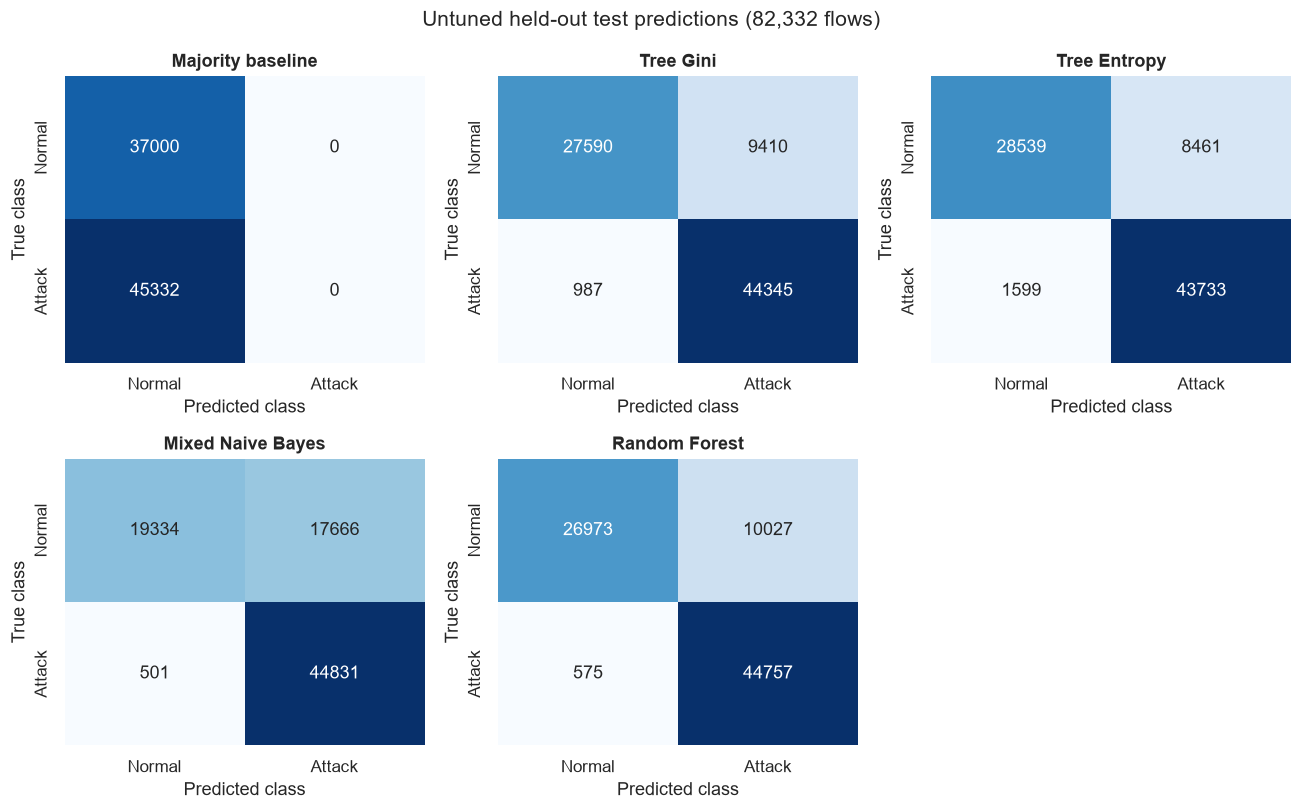

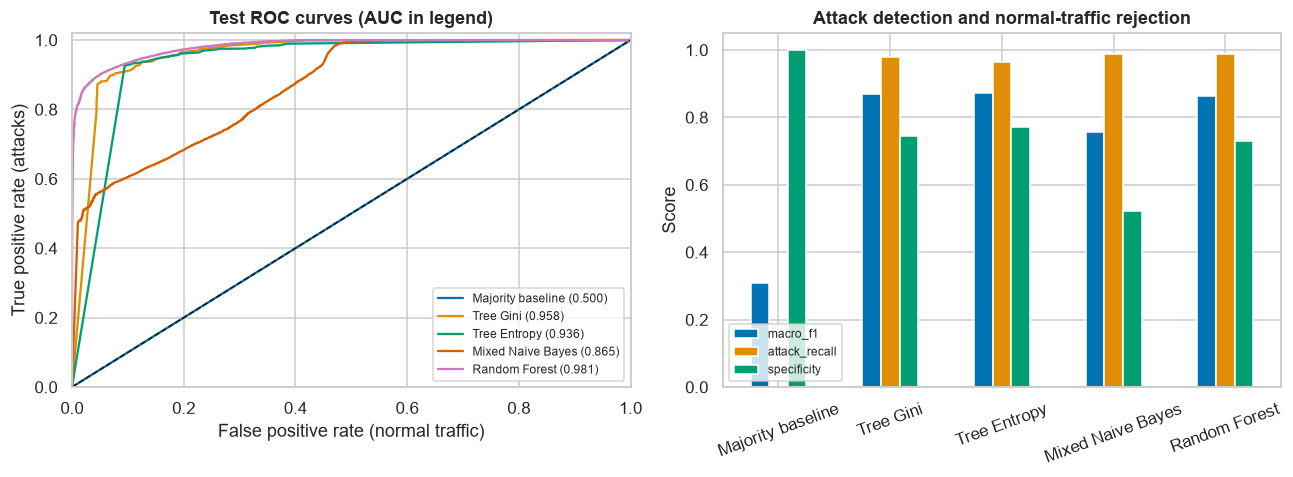

Unique-test-identity sensitivity check; no re-tuning or selection:


,model,unique_test_rows,accuracy,macro_f1,attack_recall,specificity
0,Majority baseline,53946,0.6340,0.3880,0.0000,1.0000
1,Tree Gini,53946,0.8288,0.8262,0.9632,0.7513
2,Tree Entropy,53946,0.8346,0.8306,0.9300,0.7796
3,Mixed Naive Bayes,53946,0.6969,0.6968,0.9789,0.5341
4,Random Forest,53946,0.8229,0.8208,0.9768,0.7341


In [14]:
def evaluate_predictions(y_true, predictions, probability):
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(y_true, predictions),
            'attack_precision': precision_score(y_true, predictions, pos_label=1, zero_division=0),
            'attack_recall': recall_score(y_true, predictions, pos_label=1, zero_division=0),
            'attack_f1': f1_score(y_true, predictions, pos_label=1, zero_division=0),
            'specificity': tn/(tn+fp) if tn+fp else 0.,
            'macro_f1': f1_score(y_true, predictions, average='macro', zero_division=0),
            'roc_auc': roc_auc_score(y_true, probability), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}

final_models, test_predictions, test_probabilities, final_records = {}, {}, {}, []
for name, parameters in selected_parameters.items():
    model = build_model(name, parameters)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter()-start
    start = time.perf_counter()
    prediction = model.predict(X_test)
    predict_seconds = time.perf_counter()-start
    start = time.perf_counter()
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    probability_seconds = time.perf_counter()-start
    final_models[name], test_predictions[name], test_probabilities[name] = model, prediction, probability
    metrics = evaluate_predictions(y_test, prediction, probability)
    final_records.append({'model': name, **metrics, 'train_seconds': fit_seconds,
                          'predict_seconds': predict_seconds, 'probability_seconds': probability_seconds})
    print(f'{name}: fit {fit_seconds:.2f}s; predict {predict_seconds:.3f}s; '
          f'test accuracy {metrics["accuracy"]:.4f}; macro F1 {metrics["macro_f1"]:.4f}')
    if name != 'Majority baseline':
        assert model.named_steps['select'].fit_rows_ == len(X_train)

test_results = pd.DataFrame(final_records).set_index('model')
metric_columns = ['accuracy', 'attack_precision', 'attack_recall', 'attack_f1', 'specificity', 'macro_f1', 'roc_auc']
display(test_results[metric_columns].round(4))
display(test_results[['TN', 'FP', 'FN', 'TP', 'train_seconds', 'predict_seconds', 'probability_seconds']].round(4))

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, name in zip(axes.flat, final_models):
    matrix = confusion_matrix(y_test, test_predictions[name], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
    ax.set(title=name, xlabel='Predicted class', ylabel='True class')
axes.flat[-1].axis('off')
fig.suptitle(f'Untuned held-out test predictions ({len(y_test):,} flows)', fontsize=14)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, probability in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability, pos_label=1)
    axes[0].plot(fpr, tpr, label=f'{name} ({test_results.loc[name, "roc_auc"]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set(xlabel='False positive rate (normal traffic)', ylabel='True positive rate (attacks)',
            title='Test ROC curves (AUC in legend)', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8, loc='lower right')
test_results[['macro_f1', 'attack_recall', 'specificity']].plot.bar(ax=axes[1], rot=20, ylim=(0, 1.05))
axes[1].set(title='Attack detection and normal-traffic rejection', ylabel='Score', xlabel='')
axes[1].legend(fontsize=8, loc='lower left')
fig.tight_layout()
plt.show()

# Sensitivity check reports deduplicated test performance after decisions are already fixed.
unique_test_mask = ~test_identity.duplicated(keep='first')
sensitivity = []
for name in final_models:
    row = evaluate_predictions(y_test.loc[unique_test_mask], test_predictions[name][unique_test_mask],
                               test_probabilities[name][unique_test_mask])
    sensitivity.append({'model': name, 'unique_test_rows': int(unique_test_mask.sum()),
                        'accuracy': row['accuracy'], 'macro_f1': row['macro_f1'],
                        'attack_recall': row['attack_recall'], 'specificity': row['specificity']})
print('Unique-test-identity sensitivity check; no re-tuning or selection:')
display(pd.DataFrame(sensitivity).round(4))

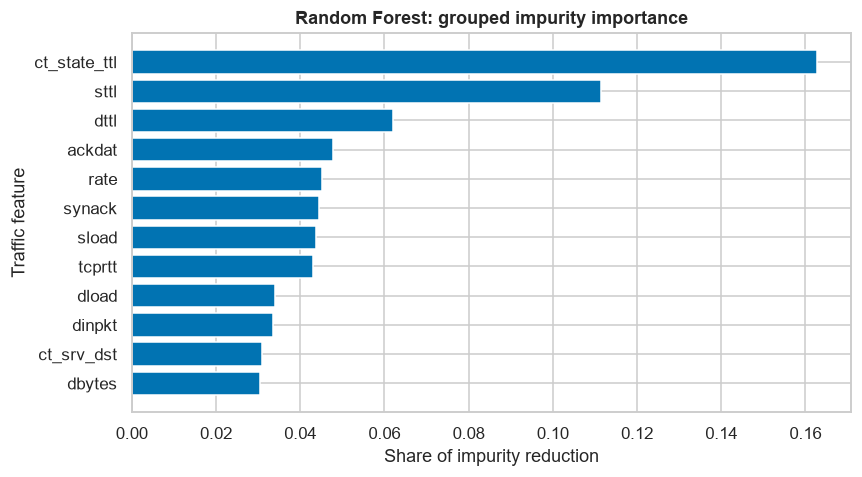

Final forest: 40 raw features, 63 encoded columns, 64 trees.
Final selector constants: []
Final selector near-redundant columns: ['ct_ftp_cmd', 'ct_flw_http_mthd']


,feature,importance
31,ct_state_ttl,0.1628
9,sttl,0.1115
10,dttl,0.0620
25,ackdat,0.0477
8,rate,0.0451
24,synack,0.0445
11,sload,0.0438
23,tcprtt,0.0431
12,dload,0.0341
16,dinpkt,0.0336


Impurity importances can favour high-cardinality attributes and distribute importance across correlated variables. They describe this model and are not evidence of causation.

In [15]:
# Impurity-based importances summarize the fitted forest, not causal effects.
forest = final_models['Random Forest']
retained = forest.named_steps['select'].columns_
preprocessor = forest.named_steps['preprocess']
encoded_names = preprocessor.get_feature_names_out()
encoded_importances = forest.named_steps['model'].feature_importances_
importance_rows = []
for raw in retained:
    # Summing categorical indicator importances brings them back to a raw-feature scale.
    mask = np.array([name == f'numeric__{raw}' or name.startswith(f'categorical__{raw}_') for name in encoded_names])
    importance_rows.append({'feature': raw, 'importance': float(encoded_importances[mask].sum())})
feature_importance = pd.DataFrame(importance_rows).sort_values('importance', ascending=False)
assert np.isclose(feature_importance.importance.sum(), 1.)
fig, ax = plt.subplots(figsize=(8, 4.5))
top_importance = feature_importance.head(12).iloc[::-1]
ax.barh(top_importance.feature, top_importance.importance)
ax.set(title='Random Forest: grouped impurity importance', xlabel='Share of impurity reduction', ylabel='Traffic feature')
fig.tight_layout()
plt.show()
print(f'Final forest: {len(retained)} raw features, {len(encoded_names)} encoded columns, 64 trees.')
print('Final selector constants:', forest.named_steps['select'].constants_)
print('Final selector near-redundant columns:', forest.named_steps['select'].redundant_)
display(feature_importance.head(10).round(4))
display(Markdown('Impurity importances can favour high-cardinality attributes and distribute importance '
                 'across correlated variables. They describe this model and are not evidence of causation.'))

## 10. Measured findings, coverage and limitations

The findings below are computed from this execution's tables. The overall model choice remains the one determined by validation, even if another family has a higher test score.

In [16]:
chosen_metrics = test_results.loc[chosen_model_name]
baseline_metrics = test_results.loc['Majority baseline']
forest_metrics = test_results.loc['Random Forest']
entropy_metrics = test_results.loc['Tree Entropy']
gini_metrics = test_results.loc['Tree Gini']
display(Markdown(
    f'**Evaluation population:** {len(X_train):,} eligible training flows (from {len(raw_train):,} raw rows), '
    f'{len(y_test):,} valid held-out test flows. The model chosen before testing was **{chosen_model_name}**.\n\n'
    f'It measured **{chosen_metrics.accuracy:.2%} accuracy**, **{chosen_metrics.attack_precision:.2%} attack precision**, '
    f'**{chosen_metrics.attack_recall:.2%} attack recall**, **{chosen_metrics.attack_f1:.4f} attack F1**, '
    f'**{chosen_metrics.specificity:.2%} specificity**, **{chosen_metrics.macro_f1:.4f} macro F1** and '
    f'**{chosen_metrics.roc_auc:.4f} ROC-AUC**. It flagged **{int(chosen_metrics.FP):,} normal flows** '
    f'as attacks and missed **{int(chosen_metrics.FN):,} attacks**. These two error types have different operational costs.\n\n'
    f'The majority baseline had accuracy **{baseline_metrics.accuracy:.2%}**, macro F1 **{baseline_metrics.macro_f1:.4f}** '
    f'and specificity **{baseline_metrics.specificity:.2%}**. This shows why accuracy alone is insufficient.\n\n'
    f'**Beyond-class forest:** test macro F1 **{forest_metrics.macro_f1:.4f}**, AUC **{forest_metrics.roc_auc:.4f}**, '
    f'fit time **{forest_metrics.train_seconds:.2f} s**, label prediction **{forest_metrics.predict_seconds:.3f} s**. '
    f'For comparison, Gini and entropy trees measured macro F1 **{gini_metrics.macro_f1:.4f}** '
    f'and **{entropy_metrics.macro_f1:.4f}**. The forest versus the better tree changed test macro F1 by '
    f'**{forest_metrics.macro_f1-max(gini_metrics.macro_f1, entropy_metrics.macro_f1):+.4f}** and took '
    f'**{forest_metrics.train_seconds/max(gini_metrics.train_seconds, 1e-12):.1f}×** the Gini tree fit time.\n\n'
    f'**Pattern mining:** the same {len(transactions):,} training flows produced '
    f'**{len(frequent_by_support[.20])}**, **{len(frequent_by_support[.30])}** and '
    f'**{len(frequent_by_support[.40])}** frequent sets at supports .20/.30/.40. All five miners agreed on '
    f'the itemsets and exact counts. Lower-support and attack-consequent rules remain descriptive training analyses.'))

coverage = pd.DataFrame([
    ('KDD and descriptive statistics', '48; 19–47', 'Implemented', 'Original training plots; fit-only byte boxplot and seeded scatter'),
    ('Cleaning, integration and quality', '51–59', 'Implemented', 'Invalid-value policy, schema alignment, duplicates and split overlap'),
    ('Feature subset selection / reduction', '60–61', 'Implemented', 'Constants and near-redundancy removed on fit data; mining samples'),
    ('Transformations actually used', '62–64', 'Used in primary pipelines', 'NB median/log/z-score; trees median/one-hot; mining training quantile bins'),
    ('Normalization comparison', '63; Lab4 Task1', 'Demonstrated only', 'Raw fit sbytes: min-max, z-score, strict decimal scaling; constant-input checks'),
    ('Bin smoothing', '57; 64; Lab4 Task1', 'Demonstrated only', '5/10 rank bins on ≤5,000 fit values; mean/median/boundary; no model/mining use'),
    ('IQR and skewness diagnostics', '30–44; Lab5', 'Diagnostic only', 'Fit-only fences and actual skewness; valid extremes retained'),
    ('Apriori / FP-Growth', '70–90', 'Implemented (library)', 'Bounded frequent sets, counts and rule grid'),
    ('DIC', '91–97', 'Implemented (educational)', 'Circular stations and four states; tiny and real checks'),
    ('Hash-based Apriori', '98–105', 'Implemented (educational)', 'Pair buckets prune candidates; exact count verification'),
    ('Vertical transaction IDs', '110', 'Implemented (educational)', 'Prefix recursion with TID intersections'),
    ('Closed / maximal frequent sets', '114–124', 'Implemented within bound', 'Post-analysis among sets of length ≤3'),
    ('Decision trees, Gini and information gain', '133–142', 'Implemented / explained', 'CART-style Gini and entropy trees; formulas explained'),
    ('Classifier evaluation / ROC', '143–149', 'Implemented', 'Held-out scores, confusion matrices, ROC curves and measured times'),
    ('Naive Bayes and smoothing', '150–158', 'Implemented', 'Mixed likelihoods, categorical smoothing, variance floor and checks'),
    ('Random Forest', 'Additional concept', 'Implemented beyond class', 'Bootstrap ensemble, random split features, validation search, evaluation'),
    ('ID3, C4.5 gain ratio, SLIQ', '136; 140', 'Explained / identified only', 'No implementation claim for these named tree algorithms'),
    ('Full DHP, partition/sampling variants, A-Close, Pincer Search', '98; 111–132', 'Not implemented', 'Our hash variant and bounded closed/maximal checks do not implement these algorithms')],
    columns=['concept', 'course PDF pages', 'status', 'evidence / scope'])
display(coverage)

**Evaluation population:** 99,607 eligible training flows (from 175,341 raw rows), 82,332 valid held-out test flows. The model chosen before testing was **Random Forest**.

It measured **87.12% accuracy**, **81.70% attack precision**, **98.73% attack recall**, **0.8941 attack F1**, **72.90% specificity**, **0.8649 macro F1** and **0.9814 ROC-AUC**. It flagged **10,027 normal flows** as attacks and missed **575 attacks**. These two error types have different operational costs.

The majority baseline had accuracy **44.94%**, macro F1 **0.3101** and specificity **100.00%**. This shows why accuracy alone is insufficient.

**Beyond-class forest:** test macro F1 **0.8649**, AUC **0.9814**, fit time **54.60 s**, label prediction **0.744 s**. For comparison, Gini and entropy trees measured macro F1 **0.8683** and **0.8735**. The forest versus the better tree changed test macro F1 by **-0.0086** and took **8.0×** the Gini tree fit time.

**Pattern mining:** the same 5,000 training flows produced **66**, **18** and **13** frequent sets at supports .20/.30/.40. All five miners agreed on the itemsets and exact counts. Lower-support and attack-consequent rules remain descriptive training analyses.

,concept,course PDF pages,status,evidence / scope
0,KDD and descriptive statistics,48; 19–47,Implemented,Original training plots; fit-only byte boxplot and seeded scatter
1,"Cleaning, integration and quality",51–59,Implemented,"Invalid-value policy, schema alignment, duplicates and split overlap"
2,Feature subset selection / reduction,60–61,Implemented,Constants and near-redundancy removed on fit data; mining samples
3,Transformations actually used,62–64,Used in primary pipelines,NB median/log/z-score; trees median/one-hot; mining training quantile bins
4,Normalization comparison,63; Lab4 Task1,Demonstrated only,"Raw fit sbytes: min-max, z-score, strict decimal scaling; constant-input checks"
5,Bin smoothing,57; 64; Lab4 Task1,Demonstrated only,"5/10 rank bins on ≤5,000 fit values; mean/median/boundary; no model/mining use"
6,IQR and skewness diagnostics,30–44; Lab5,Diagnostic only,Fit-only fences and actual skewness; valid extremes retained
7,Apriori / FP-Growth,70–90,Implemented (library),"Bounded frequent sets, counts and rule grid"
8,DIC,91–97,Implemented (educational),Circular stations and four states; tiny and real checks
9,Hash-based Apriori,98–105,Implemented (educational),Pair buckets prune candidates; exact count verification


**Limitations.** Dataset provenance and preprocessing comparability are summarized in Section 2. Repeated test flows can change metric weights; the unique-identity check shows that sensitivity. The held-out class distribution can differ from training.

The data comes from a controlled cyber range rather than this institute's live network. Binary scores do not measure per-attack-family recognition. Flow aggregation features may require completed traffic observations; there is no claim of real-time performance. The validation search is small and uses one seeded split. Probabilities are uncalibrated, and a default decision does not encode operational investigation costs. Mixed NB's Gaussian/independence assumptions remain approximations despite log transforms and correlation reduction.

Mining uses eight attributes, at most 5,000 training flows and itemsets of length ≤3. High support hides rare attack combinations; the lower-support experiment is explicitly supplementary. Rules do not demonstrate generalization or causality. Closed/maximal flags apply only within the search bound. Timings depend on CPU, libraries and host load and use three mining repetitions. This is a CPU-based study of big-data concepts on a prepared partition, with no distributed-scale performance claim.

Normalization alternatives and rank-bin smoothing are bounded learning demonstrations, not added classifier transforms. IQR flags do not establish bad data; valid extremes are retained. The log-skewness comparison reports observations, not a guaranteed improvement.

## 11. Attribution, tested setup and rerun

The supplied slides are the course context. Dataset source: [UNSW-NB15 documentation](https://research.unsw.edu.au/projects/unsw-nb15-dataset); downloaded prepared CSVs: [Mireu-Lab mirror](https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15/tree/3eb02c4a0a29866b7abcb5ef77c45cf4fcc8f6b0). The official page grants academic research use and asks users to cite these five publications. The mirror's displayed license is separate from that official attribution.

1. Nour Moustafa and Jill Slay (2015). *UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set).* MilCIS. [Publication](https://ieeexplore.ieee.org/document/7348942).
2. Nour Moustafa and Jill Slay (2016). *The evaluation of Network Anomaly Detection Systems: Statistical analysis of the UNSW-NB15 data set and the comparison with the KDD99 data set.* Information Security Journal. [Publication](https://doi.org/10.1080/19393555.2015.1125974).
3. Nour Moustafa et al. (2017). *Novel geometric area analysis technique for anomaly detection using trapezoidal area estimation on large-scale networks.* IEEE Transactions on Big Data. See the linked [official bibliography](https://research.unsw.edu.au/projects/unsw-nb15-dataset).
4. Nour Moustafa et al. (2017). *Big data analytics for intrusion detection system: statistical decision-making using finite Dirichlet mixture models.* Data Analytics and Decision Support for Cybersecurity, pp. 127–156. See the [official bibliography](https://research.unsw.edu.au/projects/unsw-nb15-dataset).
5. Mohanad Sarhan, Siamak Layeghy, Nour Moustafa and Marius Portmann (2020). *NetFlow Datasets for Machine Learning-Based Network Intrusion Detection Systems.* [Paper](https://arxiv.org/abs/2011.09144).

Implementation documentation: [sklearn decision trees](https://scikit-learn.org/stable/modules/tree.html), [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html), [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forest), [mlxtend Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/), and [FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/). The mixed NB and three educational miners are implemented in this notebook.

Tested on Windows with CPython 3.13.12. The dependency table in Section 1 records the versions actually imported by the execution kernel. To rebuild the same direct dependency environment in this folder (PowerShell, `uv` installed):

```powershell
uv venv --python 3.13.12 .venv
uv pip install --python .venv\Scripts\python.exe numpy==2.5.3 pandas==3.0.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2 seaborn==0.13.2 mlxtend==0.25.0 nbformat==5.11.1 nbclient==0.11.0 ipykernel==7.4.0 requests==2.34.2 psutil==7.2.2
```

Select `.venv\Scripts\python.exe` as the kernel in a notebook-capable editor, restart it, and run all cells in order. In an existing environment, rerun the installation command only if dependencies are missing. A terminal alternative that executes and saves this same notebook is:

```powershell
.venv\Scripts\python.exe -c "import nbformat; from nbclient import NotebookClient; p='Network_Traffic_Project.ipynb'; n=nbformat.read(p,as_version=4); NotebookClient(n,timeout=1800,kernel_name='python3',resources={'metadata':{'path':'.'}}).execute(); nbformat.write(n,p)"
```

Run from the notebook's folder. `ipykernel` supplies the `python3` kernel used by this environment. The explicit mapping in Section 2 downloads missing pinned CSVs directly into their canonical local destinations. Cached files are reused only when their expected SHA-256, row count and schema match; a conflicting file is never overwritten. Keep the saved notebook outputs with their corresponding raw CSV hashes. Rerunning on another computer will change timings. No model/result files are exported.

## 12. Final consistency checks

These checks fail loudly for altered raw files, predictors containing targets, leaked identities, mismatched supports, invalid metric ranges or incorrectly counted test populations. Passing them is separate from achieving a high score.

Additional checks cover normalization bounds and constant inputs, strict/minimal decimal scaling, stable rank-bin membership and row identity, smoothing arithmetic, seeded sample limits, unchanged primary inputs, and three mining repetitions.

In [17]:
for row in manifest:
    assert sha256_file(DATA/row['file']) == row['sha256'] == row['expected_sha256'], 'Raw CSV changed during execution'
    assert row['source_url'] == URLS[row['file']] and MIRROR_REVISION in row['source_url']
    assert row['mirror_file'] == SOURCES[row['role']]['mirror_file']
assert (len(raw_train), len(X_train), len(X_test)) == (175341, 99607, 82332)
assert train_name == 'UNSW_NB15_training-set.csv' and test_name == 'UNSW_NB15_testing-set.csv'
assert list(X_train.columns) == PREDICTORS == list(X_test.columns)
assert not set(PREDICTORS) & {'id', 'attack_cat', 'label'}
assert not (set(train_identity) & set(test_identity))
assert not (set(train_identity.iloc[fit_idx]) & set(train_identity.iloc[val_idx]))
assert all(final_models[name].named_steps['select'].fit_rows_ == len(X_train)
           for name in final_models if name != 'Majority baseline')
assert test_results[metric_columns].ge(0).all().all() and test_results[metric_columns].le(1).all().all()
assert np.isfinite(test_results.select_dtypes(include=np.number).to_numpy()).all()
assert test_results[['train_seconds', 'predict_seconds', 'probability_seconds']].ge(0).all().all()
assert (test_results[['TN', 'FP', 'FN', 'TP']].sum(axis=1) == len(y_test)).all()
assert np.isclose(test_results.loc['Majority baseline', 'roc_auc'], .5)
assert pattern_results.groupby('support')['frequent_itemsets'].nunique().eq(1).all()
assert correctness_checks > 0 and bounded_real_checks == 15
assert all(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all() for p in test_probabilities.values())
assert descriptive_demo_checked and normalization_demo_checked and smoothing_demo_checked and iqr_skew_demo_checked
assert all(frame_fingerprint(frame) == refinement_before[name] for name, frame in refinement_frames.items())
assert runtime_results.repeats.eq(3).all() and len(runtime_results) == 3*len(MINERS)
assert len(scatter_view) <= 3000 and len(smoothing_sample) <= 5000
finished_at = datetime.now(timezone(timedelta(hours=5, minutes=30)))
print('PASS: raw-file preservation, unchanged primary inputs, training-only fitting, split identities, '
      'normalization/smoothing/diagnostic checks, three-repeat mining counts, metrics and test totals.')
print(f'Completed: {finished_at.isoformat(timespec="seconds")} (Asia/Kolkata offset).')
print(f'Total measured notebook execution time: {time.perf_counter()-RUN_START:.1f} seconds.')
print(f'Classification: {len(X_train):,} training / {len(X_test):,} test rows; mining: {MAIN_N:,} training transactions.')
display(Markdown('**Executed project complete.** Outputs above are measured results from this kernel. '
                 'The notebook and two raw CSVs are the project artifacts for this stage.'))

PASS: raw-file preservation, unchanged primary inputs, training-only fitting, split identities, normalization/smoothing/diagnostic checks, three-repeat mining counts, metrics and test totals.
Completed: 2026-10-10T16:56:58+05:30 (Asia/Kolkata offset).
Total measured notebook execution time: 189.3 seconds.
Classification: 99,607 training / 82,332 test rows; mining: 5,000 training transactions.


**Executed project complete.** Outputs above are measured results from this kernel. The notebook and two raw CSVs are the project artifacts for this stage.